# NumPy, Pandas and Matplotlib 🎓

This notebook covers the three libraries that every Data Science and AI program stands on: **NumPy** for fast numerical work, **Pandas** for working with tables of data, and **Matplotlib** for drawing graphs.

By the end of this notebook you will be able to:

- Create and work with **NumPy arrays**.
- Load, inspect, clean, filter and summarise data using **Pandas**.
- Create basic and customised **visualizations** using Matplotlib.

Throughout the notebook we will also **break the code on purpose**. Errors are not your enemy. Reading an error message correctly is one of the most useful skills you can build, so we will meet the common ones here before they surprise you in an exam or in a project.

### 🎓 Topics from the university PDF

This notebook follows the university PDF **"Unit 1 - DS&AI"** (the NumPy, Pandas and Matplotlib part, slides 37 to 69) and adds more explanation, error cases and extra topics on top of it.

**How to spot them:** every heading marked with 🎓 is a topic that is in the university PDF. Headings **without** the marker are extra material added to this notebook. Everything marked is what your course expects, so start there if you are short of time.

| PDF slide | Topic in the university PDF | Where to find it in this notebook |
|---|---|---|
| 38 | Why these libraries? | Title and the intro section above |
| 39 | Learning objectives | Title section above |
| 41 | Introduction to NumPy | NumPy - Numerical Python |
| 42 | Why NumPy over lists? | Why NumPy over lists? |
| 43 | Creating NumPy arrays | Creating arrays |
| 44 | Array attributes (`shape`, `size`, `dtype`) | Array attributes |
| 45 | Array indexing and slicing (1D and 2D) | Indexing and slicing |
| 46 | Mathematical operations | Mathematical operations |
| 47 | NumPy functions (`mean`, `median`, `std`, `sum`, `max`) | Statistical and aggregate functions |
| 49 | Introduction to Pandas (Series and DataFrame) | Pandas - Data Analysis |
| 50 | Pandas Series | Pandas Series |
| 51 | Pandas DataFrame | Pandas DataFrame |
| 52 | Reading and writing data | Reading and writing data |
| 53 | Inspecting DataFrames (`head`, `tail`, `shape`, `info`, `describe`) | Inspecting a DataFrame |
| 54 | Selecting data | Selecting data |
| 55 | Filtering data | Filtering data |
| 56 | Adding and removing columns | Adding, changing and removing columns |
| 57 | Handling missing data (`fillna`, `dropna`) | Handling missing data |
| 58 | GroupBy and aggregation | Grouping and aggregation |
| 60 | Introduction to Matplotlib | Matplotlib - Data Visualization |
| 61 | Basic plot | Your first plot |
| 62 | Scatter plot | Scatter plot |
| 63 | Bar chart | Bar chart |
| 64 | Histogram | Histogram |
| 65 | Pie chart | Pie chart |
| 66 | Customizing plots | Customizing plots |
| 67 | Example: data analysis and visualization | Putting it all together: sales analysis |
| 68 | Summary | Summary |
| 69 | Exercise | Practice questions |

## Before we begin: libraries

In the first module we used functions like `print()` and `input()` which Python gives us for free. But Python cannot ship with everything. For specialised work, people write **libraries** (also called **packages** or **modules**), which are collections of ready-made code that we can bring into our program.

To use a library, we first have to **import** it.

| Library | What it gives us | Usual import |
|---|---|---|
| NumPy | Fast arrays and mathematical operations | `import numpy as np` |
| Pandas | Tables (DataFrames) and data analysis tools | `import pandas as pd` |
| Matplotlib | Graphs and charts | `import matplotlib.pyplot as plt` |

The `as np`, `as pd` and `as plt` parts give the library a short **alias** (a nickname), so we type `np.array(...)` instead of `numpy.array(...)`. These aliases are a universal convention. Everyone writes them the same way, so you will see them in every tutorial and in every exam paper.

#### How the code cells in this notebook are written

In the first module, a variable made in one cell was often reused in the next. Here, **every code cell is self-contained**. Each one starts with its own `import` lines and creates all the data it needs (arrays, DataFrames, lists) before using it. 

This means you can run **any cell on its own, in any order**, and it will work. The price is that you will see the same few lines repeated (for example the employee table), but that is intentional: it also shows you what a complete, runnable program looks like.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.5.4
Pandas version: 3.0.6


All three imported without any complaint, so they are installed. (Google Colab has them pre-installed. On your own computer you would install them once from the terminal using `pip install numpy pandas matplotlib`.)

Let's see what happens if we import something that does not exist, or misspell a name.

In [2]:
import numpyy as np

ModuleNotFoundError: No module named 'numpyy'

We get a `ModuleNotFoundError: No module named 'numpyy'`.

Python searched for a library with that exact name and could not find it. Either the name is misspelled (as here), or the library is not installed on this machine. Names are **case-sensitive** too, so `import Numpy` would fail in the same way.

Here is another common mistake: importing correctly but then using the wrong alias.

In [3]:
import numpy as np

arr = numpy.array([1, 2, 3])

NameError: name 'numpy' is not defined

This gives `NameError: name 'numpy' is not defined`.

We wrote `import numpy as np`, which means the library is now available **only** under the name `np`. The full name `numpy` was never created in our program. The fix is simply to use the alias we chose.

In [4]:
import numpy as np

arr = np.array([1, 2, 3])
print(arr)

[1 2 3]


Now we are ready. Let's start with NumPy.

## NumPy - Numerical Python 🎓

**NumPy** stands for **Numerical Python**. It is the foundation of almost the entire Python data science world. Pandas is built on top of it, and libraries for machine learning such as Scikit-learn, TensorFlow and PyTorch all depend on it.

NumPy is used for:

- High-performance **multi-dimensional arrays**.
- **Mathematical operations** on large amounts of data.
- Linear algebra, statistics and random number generation.

The central object of NumPy is the **`ndarray`** (n-dimensional array), usually just called an **array**.

### Why NumPy over lists? 🎓

We already know Python **lists** from the previous module. They can store numbers, so why do we need something new?

Suppose you have the marks of students stored in a list and you want to add `5` grace marks to every student. Let's try the natural thing first.

In [5]:
marks = [40, 55, 62, 78]
print(marks + 5)

TypeError: can only concatenate list (not "int") to list

This gives a `TypeError: can only concatenate list (not "int") to list`.

For a list, the `+` operator means **joining** two lists together. It does not know that we meant "add 5 to each element". With a list, we would have to write a loop.

In [6]:
marks = [40, 55, 62, 78]

new_marks = []
for m in marks:
  new_marks.append(m + 5)

print(new_marks)

[45, 60, 67, 83]


That works, but it is a lot of code for a tiny job. Now the same task with a NumPy array.

In [7]:
import numpy as np

marks = np.array([40, 55, 62, 78])

print(marks + 5)
print(marks * 2)

[45 60 67 83]
[ 80 110 124 156]


The operation was applied to **every element at once**, with no loop. This is called a **vectorized operation**, and it is the single most important idea in NumPy.

It is also much faster. Let's measure it with a million numbers. (The exact times will differ on every computer, but the gap will be obvious.)

In [8]:
import numpy as np

import time

size = 1_000_000
py_list = list(range(size))
np_array = np.arange(size)

start = time.time()
doubled_list = [x * 2 for x in py_list]
print("List  :", round(time.time() - start, 4), "seconds")

start = time.time()
doubled_array = np_array * 2
print("NumPy :", round(time.time() - start, 4), "seconds")

List  : 0.0721 seconds
NumPy : 0.0029 seconds


| Feature | Python List | NumPy Array |
|---|---|---|
| Speed | Slower | Much faster (the work is done in compiled C code) |
| Memory usage | More | Less, since all elements share one type |
| Mathematical operations | Needs manual loops | Built-in vectorized operations |
| Element types | Can mix different types | All elements have the **same** type |
| `+` operator | Joins two lists | Adds element by element |

### Creating arrays 🎓

The most direct way to make an array is to give a list to `np.array()`.

In [9]:
import numpy as np

arr1 = np.array([1, 2, 3, 4])
print(arr1)
print(type(arr1))

[1 2 3 4]
<class 'numpy.ndarray'>


Notice that the printed array has **no commas** between the numbers. That is how NumPy shows an array, and it is a quick way to tell an array apart from a list when you look at the output.

For a **2D array** (rows and columns, like a table or a matrix), we give a list of lists. Each inner list becomes one row.

In [10]:
import numpy as np

arr2 = np.array([[1, 2, 3],
                 [4, 5, 6]])
print(arr2)

[[1 2 3]
 [4 5 6]]


Each element of an array must have the same datatype. Let's see what NumPy does if we mix them.

In [11]:
import numpy as np

mixed = np.array([1, 2.5, 3])
print(mixed)

mixed2 = np.array([1, "two", 3])
print(mixed2)

[1.  2.5 3. ]
['1' 'two' '3']


NumPy does not complain. It **upcasts** everything to a type that can hold all the values:

- Integers mixed with a float all become floats (`1.` is `1.0`).
- Numbers mixed with a string all become strings.

This is helpful, but it can quietly cause trouble later (you cannot do maths on strings), so always check what you built.

Now let's try an array where the rows have **different lengths**.

In [12]:
import numpy as np

ragged = np.array([[1, 2, 3], [4, 5]])

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.

This gives a `ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape...`

An array must be a perfect rectangle: every row must have the same number of columns. A "ragged" list of lists cannot be turned into a rectangular array, so NumPy refuses. (A plain Python list has no such restriction.)

Typing every number by hand is not practical, so NumPy gives us functions that build common arrays for us.

In [13]:
import numpy as np

print(np.zeros((2, 3)))
print()
print(np.ones((3, 3)))
print()
print(np.full((2, 2), 7))
print()
print(np.eye(3))

[[0. 0. 0.]
 [0. 0. 0.]]

[[1. 1. 1.]
 [1. 1. 1.]
 [1. 1. 1.]]

[[7 7]
 [7 7]]

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


- `np.zeros((2, 3))` makes an array of zeros with 2 rows and 3 columns.
- `np.ones((3, 3))` makes a 3x3 array of ones.
- `np.full((2, 2), 7)` fills a 2x2 array with the value we choose.
- `np.eye(3)` makes the 3x3 **identity matrix** (ones on the diagonal, zeros elsewhere). We will meet this again with matrices.

Notice that the shape goes inside **one pair of parentheses as a tuple** `(2, 3)`, so there are two brackets. Forgetting that is a classic mistake.

In [14]:
import numpy as np

np.zeros(2, 3)

TypeError: Cannot interpret '3' as a data type

We get `TypeError: Cannot interpret '3' as a data type`.

`np.zeros` expects the shape as its **first** argument. We passed `2` and `3` as two separate arguments, so NumPy took `3` to be the second parameter (the `dtype`), which makes no sense. Wrapping the shape in a tuple, `np.zeros((2, 3))`, fixes it.

Now the functions that create **sequences of numbers**.

In [15]:
import numpy as np

print(np.arange(0, 10, 2))
print(np.arange(5))
print(np.linspace(0, 1, 5))

[0 2 4 6 8]
[0 1 2 3 4]
[0.   0.25 0.5  0.75 1.  ]


- `np.arange(start, stop, step)` is the array version of `range()`. The `stop` value is **not** included, exactly like `range`. With a single value, `np.arange(5)` gives `0` to `4`.
- `np.linspace(start, stop, num)` gives `num` numbers **evenly spaced** between `start` and `stop`, and this time `stop` **is** included.

A simple way to remember the difference: `arange` is told the **step size**, while `linspace` is told **how many points** we want.

| Function | Creates |
|---|---|
| `np.array(list)` | Array from a list |
| `np.zeros(shape)` | Array of zeros |
| `np.ones(shape)` | Array of ones |
| `np.full(shape, value)` | Array filled with one value |
| `np.eye(n)` | Identity matrix |
| `np.arange(start, stop, step)` | Numbers with a fixed step |
| `np.linspace(start, stop, num)` | A fixed count of evenly spaced numbers |

### Array attributes 🎓

Every array carries some information about itself. These are called **attributes**, and we read them without brackets (they are not function calls).

In [16]:
import numpy as np

arr = np.array([[1, 2, 3],
                [4, 5, 6]])

print("Dimensions (ndim):", arr.ndim)
print("Shape            :", arr.shape)
print("Size             :", arr.size)
print("Datatype (dtype) :", arr.dtype)

Dimensions (ndim): 2
Shape            : (2, 3)
Size             : 6
Datatype (dtype) : int64


| Attribute | Meaning | Value here |
|---|---|---|
| `ndim` | Number of dimensions (1D, 2D, ...) | `2` |
| `shape` | Rows and columns, as a tuple | `(2, 3)` means 2 rows and 3 columns |
| `size` | Total number of elements | `6` (which is 2 x 3) |
| `dtype` | Datatype of the elements | `int64` (on some older Windows setups you may see `int32`) |

The `shape` attribute is the one you will use the most. Always read it as **(rows, columns)**.

A common mistake is to write these attributes like functions.

In [17]:
import numpy as np

arr = np.array([[1, 2, 3],
                [4, 5, 6]])

print(arr.shape())

TypeError: 'tuple' object is not callable

This gives `TypeError: 'tuple' object is not callable`.

`arr.shape` is **already** the finished tuple `(2, 3)`. Adding `()` after it tells Python to *call* that tuple like a function, which is impossible. Compare this with `arr.mean()` or `arr.sum()`, which really are functions and need the brackets.

### Changing the datatype

We can convert an array to another datatype with `astype()`, just like the type casting we did with `int()` and `float()`.

In [18]:
import numpy as np

floats = np.array([1.7, 2.2, 3.9])
print(floats.dtype)

ints = floats.astype(int)
print(ints)
print(ints.dtype)

float64
[1 2 3]
int64


The decimal parts were **cut off** (truncated), not rounded: `3.9` became `3`. Converting a float to an integer always throws away information, so be careful.

And what if the conversion is impossible?

In [19]:
import numpy as np

words = np.array(["10", "20", "abc"])
print(words.astype(int))

ValueError: invalid literal for int() with base 10: np.str_('abc')

This gives `ValueError: invalid literal for int() with base 10: 'abc'`. (Depending on your NumPy version, the text may be shown as `np.str_('abc')`.)

Just like `int("abc")` in plain Python, the text `abc` has no integer representation. The strings `"10"` and `"20"` would have converted fine, but one bad value stops the whole conversion.

### Indexing and slicing 🎓

Getting values out of an array works just like lists: the index starts at `0`, and a **negative index** counts from the end.

In [20]:
import numpy as np

arr = np.array([10, 20, 30, 40, 50])

print(arr[0])
print(arr[-1])
print(arr[1:4])
print(arr[:3])
print(arr[::2])

10
50
[20 30 40]
[10 20 30]
[10 30 50]


- `arr[0]` is the first element and `arr[-1]` is the last.
- `arr[1:4]` is a **slice** from index `1` up to, but **not including**, index `4`.
- `arr[:3]` starts from the beginning, and `arr[::2]` takes every second element.

The slice format is `arr[start:stop:step]`, the same as in lists.

What if we ask for an index which does not exist?

In [21]:
import numpy as np

arr = np.array([10, 20, 30, 40, 50])

print(arr[10])

IndexError: index 10 is out of bounds for axis 0 with size 5

This gives `IndexError: index 10 is out of bounds for axis 0 with size 5`.

Our array has 5 elements, so the valid indexes are `0` to `4` (and `-1` to `-5`). The error message is helpful: it tells us the bad index, which axis it was on, and the actual size.

For **2D arrays** we give two indexes inside one pair of brackets, `[row, column]`.

In [22]:
import numpy as np

mat = np.array([[1, 2, 3],
                [4, 5, 6],
                [7, 8, 9]])

print(mat[1, 2])
print(mat[0])
print(mat[:, 1])
print(mat[0:2, 1:3])

6
[1 2 3]
[2 5 8]
[[2 3]
 [5 6]]


- `mat[1, 2]` means row `1`, column `2`, which is `6`.
- `mat[0]` gives the whole first row.
- `mat[:, 1]` means "**all** rows, column `1`", which is the entire second column.
- `mat[0:2, 1:3]` means "rows `0` to `1`, columns `1` to `2`", which is a small block from the matrix.

The colon `:` alone means "everything along this direction". Reading the part before the comma as rows and the part after as columns will keep you out of trouble.

A very common beginner mistake is to use the list style `mat[1][2]` and the NumPy style `mat[1, 2]` interchangeably in all cases. For a single element both work, but the slicing forms behave differently. See what happens with a column.

In [23]:
import numpy as np

mat = np.array([[1, 2, 3],
                [4, 5, 6],
                [7, 8, 9]])

print(mat[:, 1])
print(mat[:][1])

[2 5 8]
[4 5 6]


`mat[:, 1]` correctly gave the column `[2 5 8]`. But `mat[:][1]` gave the row `[4 5 6]`. The expression `mat[:]` is the whole matrix again, and then `[1]` takes its second **row**. So for anything beyond a single element, always use the `[row, column]` form.

#### Boolean indexing

We can also pick elements using a **condition**. This is one of the most useful tricks for data analysis.

In [24]:
import numpy as np

scores = np.array([45, 82, 67, 91, 33, 78])

print(scores > 60)
print(scores[scores > 60])

[False  True  True  True False  True]
[82 67 91 78]


A comparison like `scores > 60` is applied to every element and gives an array of `True` and `False`, called a **mask**. When we put that mask inside the square brackets, NumPy keeps only the elements where the mask is `True`.

Conditions can be combined, but there is a catch.

In [25]:
import numpy as np

scores = np.array([45, 82, 67, 91, 33, 78])

print(scores[(scores > 40) & (scores < 80)])

[45 67 78]


Here we used `&` for "and" and wrapped each condition in **parentheses**. Let's see what goes wrong with the Python keyword `and`.

In [26]:
import numpy as np

scores = np.array([45, 82, 67, 91, 33, 78])

print(scores[(scores > 40) and (scores < 80)])

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

This gives `ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()`.

The keyword `and` expects **one** `True` or `False` on each side. But `scores > 40` is a whole array of them, and Python cannot decide whether an array of six booleans counts as true or false. The rule is:

| Meaning | Use for arrays | Not |
|---|---|---|
| and | `&` | `and` |
| or | `\|` | `or` |
| not | `~` | `not` |

And always put each condition in its own parentheses, because `&` binds more tightly than `>` or `<`.

#### Slices are views, not copies

There is one subtle behaviour you must know about. When we slice an array, NumPy does **not** copy the data. The slice is a **view** into the same memory.

In [27]:
import numpy as np

original = np.array([1, 2, 3, 4, 5])
part = original[1:4]

part[0] = 99

print("part    :", part)
print("original:", original)

part    : [99  3  4]
original: [ 1 99  3  4  5]


We changed only `part`, but `original` changed too! Both names point to the same data, which saves memory but can surprise you. If you want an independent copy, ask for it explicitly with `.copy()`.

In [28]:
import numpy as np

original = np.array([1, 2, 3, 4, 5])
part = original[1:4].copy()

part[0] = 99

print("part    :", part)
print("original:", original)

part    : [99  3  4]
original: [1 2 3 4 5]


Now `original` is safe.

### Reshaping arrays

The same data can be arranged into different shapes. `reshape()` rearranges the elements without changing them.

In [29]:
import numpy as np

arr = np.arange(1, 13)
print(arr)
print(arr.shape)

print(arr.reshape(3, 4))
print()
print(arr.reshape(2, 6))

[ 1  2  3  4  5  6  7  8  9 10 11 12]
(12,)
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]]


We started with 12 numbers in a single row and arranged them as 3x4 and then as 2x6. The new shape must hold **exactly** the same number of elements: 3 x 4 = 12 and 2 x 6 = 12.

In [30]:
import numpy as np

arr = np.arange(1, 13)

print(arr.reshape(5, 3))

ValueError: cannot reshape array of size 12 into shape (5,3)

This gives `ValueError: cannot reshape array of size 12 into shape (5,3)`.

A 5x3 array needs 15 elements, but we only have 12. NumPy cannot invent three more numbers or throw three away, so it stops. Before reshaping, check that rows x columns equals `arr.size`.

If you only know one of the dimensions, write `-1` for the other and NumPy works it out.

In [31]:
import numpy as np

arr = np.arange(1, 13)

print(arr.reshape(3, -1))
print(arr.reshape(-1, 2).shape)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
(6, 2)


`reshape(3, -1)` means "3 rows, and figure out the columns yourself", which is 4.

Two more related tools: `flatten()` turns any array back into 1D, and `.T` is the **transpose**, which swaps rows and columns.

In [32]:
import numpy as np

mat = np.array([[1, 2, 3],
                [4, 5, 6]])

print(mat.shape)
print(mat.T)
print(mat.T.shape)
print(mat.flatten())

(2, 3)
[[1 4]
 [2 5]
 [3 6]]
(3, 2)
[1 2 3 4 5 6]


The original `2 x 3` matrix became `3 x 2` after the transpose: the first row `[1, 2, 3]` became the first column.

### Mathematical operations 🎓

Arithmetic on arrays is **element-wise**: each operator works on the matching positions of the two arrays.

In [33]:
import numpy as np

a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print(a + b)
print(a - b)
print(a * b)
print(b / a)
print(a ** 2)

[5 7 9]
[-3 -3 -3]
[ 4 10 18]
[4.  2.5 2. ]
[1 4 9]


Look at `a * b`: it gave `[4 10 18]`, which is `1*4`, `2*5` and `3*6`. This is **not** the matrix multiplication from mathematics. It is just element by element. (We will do true matrix multiplication shortly.)

What if the two arrays are of different lengths?

In [34]:
import numpy as np

a = np.array([1, 2, 3])
c = np.array([10, 20])

print(a + c)

ValueError: operands could not be broadcast together with shapes (3,) (2,) 

This gives `ValueError: operands could not be broadcast together with shapes (3,) (2,)`.

To add element by element, every element needs a partner. The three elements of `a` cannot be paired with only two elements of `c`. So the shapes must match, **unless** one of them follows the broadcasting rule, which we see next.

#### Broadcasting

We already used broadcasting earlier without naming it: in `marks + 5`, the single number `5` was "stretched" across the whole array. NumPy does this automatically when the shapes are compatible.

In [35]:
import numpy as np

mat = np.array([[1, 2, 3],
                [4, 5, 6]])

row = np.array([10, 20, 30])
col = np.array([[100],
                [200]])

print(mat + row)
print()
print(mat + col)

[[11 22 33]
 [14 25 36]]

[[101 102 103]
 [204 205 206]]


- `mat + row`: the row `[10, 20, 30]` was added to **each row** of the matrix.
- `mat + col`: the column `[[100], [200]]` was added to **each column**, so `100` went to every element of the first row and `200` to every element of the second.

The rule in short: NumPy compares the shapes from the **right-hand side**. Two dimensions are compatible if they are **equal**, or if one of them is **1**. When they are compatible, the size-1 side is stretched to match. If neither is true, we get the `could not be broadcast` error from above.

#### Mathematical functions

NumPy provides many mathematical functions that work on a whole array in one go.

In [36]:
import numpy as np

x = np.array([1, 4, 9, 16])

print(np.sqrt(x))
print(np.square(x))
print(np.exp(np.array([0, 1, 2])))
print(np.log(np.array([1, 10, 100])))
print(np.round(np.array([1.234, 5.678]), 1))

[1. 2. 3. 4.]
[  1  16  81 256]
[1.         2.71828183 7.3890561 ]
[0.         2.30258509 4.60517019]
[1.2 5.7]


| Function | Does |
|---|---|
| `np.sqrt(x)` | Square root of each element |
| `np.square(x)` | Square of each element |
| `np.exp(x)` | `e` raised to each element |
| `np.log(x)` | Natural logarithm of each element |
| `np.round(x, n)` | Rounds to `n` decimal places |
| `np.abs(x)` | Absolute value of each element |

Now, what if a function is given an input that is mathematically invalid?

In [37]:
import numpy as np

print(np.sqrt(np.array([4, -9])))
print(np.log(np.array([10, 0])))

[ 2. nan]
[2.30258509       -inf]


C:\Users\dwaid\AppData\Local\Temp\ipykernel_33380\4281369077.py:3: RuntimeWarning: invalid value encountered in sqrt
  print(np.sqrt(np.array([4, -9])))
C:\Users\dwaid\AppData\Local\Temp\ipykernel_33380\4281369077.py:4: RuntimeWarning: divide by zero encountered in log
  print(np.log(np.array([10, 0])))


Interesting: this time there is **no crash**. NumPy printed a `RuntimeWarning` and gave special values:

- `np.sqrt(-9)` gave **`nan`**, which stands for "Not a Number", because the square root of a negative number is not a real number.
- `np.log(0)` gave **`-inf`** (negative infinity).

Python itself would raise an error for `math.sqrt(-9)`, but NumPy prefers to continue and mark the bad results. The danger is that `nan` silently spreads through later calculations, so a warning like this deserves your attention. We will see how Pandas helps with such missing values later.

### Statistical and aggregate functions 🎓

Aggregate functions **reduce** an array to a single summary value.

In [38]:
import numpy as np

data = np.array([2, 3, 3, 5, 8])

print("Sum    :", np.sum(data))
print("Mean   :", np.mean(data))
print("Median :", np.median(data))
print("Std    :", np.std(data))
print("Var    :", np.var(data))
print("Min    :", np.min(data))
print("Max    :", np.max(data))

Sum    : 21
Mean   : 4.2
Median : 3.0
Std    : 2.1354156504062622
Var    : 4.5600000000000005
Min    : 2
Max    : 8


| Function | Purpose |
|---|---|
| `np.sum()` | Sum of all elements |
| `np.mean()` | Average |
| `np.median()` | Middle value |
| `np.std()` | Standard deviation |
| `np.var()` | Variance |
| `np.min()`, `np.max()` | Smallest and largest |
| `np.argmin()`, `np.argmax()` | **Position** of the smallest and largest |

For the data `[2, 3, 3, 5, 8]`: the mean is `(2+3+3+5+8)/5 = 4.2`, and the median is the middle value `3`. The **variance** measures how spread out the data is. It is the average of the squared distances from the mean, and the **standard deviation** is its square root.

*NumPy has no built-in function for the **mode** (the most frequent value). In Pandas we will get it from `.mode()`.*

Often we want the **position** of a value rather than the value itself.

In [39]:
import numpy as np

data = np.array([2, 3, 3, 5, 8])

print(np.max(data), "is at index", np.argmax(data))
print(np.min(data), "is at index", np.argmin(data))
print(np.cumsum(data))

8 is at index 4
2 is at index 0
[ 2  5  8 13 21]


`np.argmax` returns the index of the largest value, `np.argmin` the index of the smallest. `np.cumsum` gives the **cumulative sum**, a running total: `2`, `2+3`, `2+3+3`, and so on.

#### Aggregates on 2D arrays: the `axis` argument

For a 2D array, we can ask for a summary of the whole array, or **down the columns**, or **across the rows**. The `axis` argument chooses which.

In [40]:
import numpy as np

sales = np.array([[10, 20, 30],
                  [40, 50, 60]])

print("Whole array   :", sales.sum())
print("axis=0 (down) :", sales.sum(axis=0))
print("axis=1 (across):", sales.sum(axis=1))

Whole array   : 210
axis=0 (down) : [50 70 90]
axis=1 (across): [ 60 150]


- `axis=0` collapses the **rows**, i.e. works **down each column**: `10+40`, `20+50`, `30+60`.
- `axis=1` collapses the **columns**, i.e. works **across each row**: `10+20+30` and `40+50+60`.

A memory trick: the axis you give is the one that **disappears** from the shape. The shape was `(2, 3)`. After `axis=0` it is `(3,)`, and after `axis=1` it is `(2,)`.

If you give an axis that does not exist, you get an error.

In [41]:
import numpy as np

sales = np.array([[10, 20, 30],
                  [40, 50, 60]])

print(sales.sum(axis=2))

AxisError: axis 2 is out of bounds for array of dimension 2

This gives `AxisError: axis 2 is out of bounds for array of dimension 2`. A 2D array has only axis `0` and axis `1`.

### Matrix operations and linear algebra

In machine learning, data is stored as **vectors** (1D arrays) and **matrices** (2D arrays). NumPy gives us the tools for the linear algebra on them.

#### Vectors

A **vector** is an ordered collection of numbers, for example `(3, 4)` or `(1, 2, 3)`. The **dot product** of two vectors multiplies matching elements and adds them up, `a . b = sum of a_i * b_i`. The **norm** is the length of the vector.

In [42]:
import numpy as np

a = np.array([2, 3])
b = np.array([4, 1])

print("Dot product:", np.dot(a, b))
print("Norm of (3, 4):", np.linalg.norm(np.array([3, 4])))

Dot product: 11
Norm of (3, 4): 5.0


The dot product is `2*4 + 3*1 = 8 + 3 = 11`, and the norm of `(3, 4)` is `sqrt(3^2 + 4^2) = 5`.

#### Matrix multiplication

Matrix multiplication is different from the element-wise `*`. Each element of the result is the **row of the first matrix times the column of the second**. We use `np.dot()`, `np.matmul()` or the `@` operator.

In [43]:
import numpy as np

A = np.array([[1, 2],
              [3, 4]])
B = np.array([5, 6])

print("Element-wise A * B:")
print(A * B)

print("Matrix product A @ B:")
print(A @ B)

Element-wise A * B:
[[ 5 12]
 [15 24]]
Matrix product A @ B:
[17 39]


`A * B` multiplied element by element (and used broadcasting to stretch `B`), which is **not** the answer we want. `A @ B` is the real matrix product:

- first row: `(1 x 5) + (2 x 6) = 17`
- second row: `(3 x 5) + (4 x 6) = 39`

Matrix multiplication has a strict rule: the number of **columns of the first** matrix must equal the number of **rows of the second**. For shapes `(m, n) @ (n, p)` the result has shape `(m, p)`. Let's break the rule.

In [44]:
import numpy as np

P = np.ones((2, 3))
Q = np.ones((2, 3))

print(P @ Q)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 3)

This gives `ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0... (size 2 is different from 3)`.

`P` has 3 columns, but `Q` has only 2 rows, so the "row times column" pairing cannot be completed. The fix is to transpose `Q` so that its shape becomes `(3, 2)`.

In [45]:
import numpy as np

P = np.ones((2, 3))
Q = np.ones((2, 3))

print((P @ Q.T).shape)
print(P @ Q.T)

(2, 2)
[[3. 3.]
 [3. 3.]]


Now the inner dimensions match: `(2, 3) @ (3, 2)` gives a `(2, 2)` result.

#### Identity and inverse

The **identity matrix** `I` is the matrix version of the number `1`: multiplying by it changes nothing, `I . A = A`. The **inverse** of a matrix is the matrix version of a reciprocal: `A` times its inverse gives `I`.

In [46]:
import numpy as np

A = np.array([[1, 2],
              [3, 4]])

I = np.eye(2)
print(I @ A)

A_inv = np.linalg.inv(A)
print(A_inv)
print(np.round(A @ A_inv, 2))

[[1. 2.]
 [3. 4.]]
[[-2.   1. ]
 [ 1.5 -0.5]]
[[1. 0.]
 [0. 1.]]


`I @ A` gave back `A` unchanged. And `A @ A_inv` gave the identity matrix (we rounded it, because computers store decimals with tiny errors, so you may see numbers like `0.99999999` otherwise).

Not every matrix has an inverse. Let's try one that does not.

In [47]:
import numpy as np

S = np.array([[1, 2],
              [2, 4]])

print(np.linalg.inv(S))

LinAlgError: Singular matrix

This gives `LinAlgError: Singular matrix`.

Look at `S`: the second row is exactly **twice** the first row. Such a matrix is called **singular**, and its determinant is `0`. It carries no independent information in the second row, and just like we cannot divide by zero, we cannot invert it.

In [48]:
import numpy as np

A = np.array([[1, 2],
              [3, 4]])
S = np.array([[1, 2],
              [2, 4]])

print(np.linalg.det(A))
print(np.linalg.det(S))

-2.0000000000000004
0.0


The determinant is a quick test: if it is `0` (or practically `0`), the inverse does not exist. For `A` it is `-2` (the tiny trailing digits are the usual decimal storage error), so `A` can be inverted, while for `S` it is `0`.

#### Solving linear equations

A system of linear equations can be written as a matrix equation `AX = B`. Take this system:

```text
2x + 3y = 8
 x -  y = 2
```

The numbers in front of `x` and `y` form the matrix `A`, and the right side forms `B`. NumPy solves it with `np.linalg.solve()`.

In [49]:
import numpy as np

A = np.array([[2, 3],
              [1, -1]])
B = np.array([8, 2])

solution = np.linalg.solve(A, B)
print(solution)

x, y = solution
print("x =", x, " y =", y)

[2.8 0.8]
x = 2.8  y = 0.8


So `x = 2.8` and `y = 0.8`. We can **verify** by putting them back: `2(2.8) + 3(0.8) = 5.6 + 2.4 = 8` and `2.8 - 0.8 = 2`. Both equations hold.

Another way is `X = inverse(A) times B`, which is what the theory says. In practice, `solve()` is preferred because it is faster and more accurate than computing the inverse.

In [50]:
import numpy as np

A = np.array([[2, 3],
              [1, -1]])
B = np.array([8, 2])

print(np.linalg.inv(A) @ B)

[2.8 0.8]


Same answer. Now, a second batch of tools which you will need very often.

### Useful array tools

#### Joining arrays

`np.concatenate()` joins arrays, and `np.vstack()` / `np.hstack()` stack them vertically (one on top of the other) or horizontally (side by side).

In [51]:
import numpy as np

a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print(np.concatenate([a, b]))
print(np.vstack([a, b]))
print(np.hstack([a, b]))

[1 2 3 4 5 6]
[[1 2 3]
 [4 5 6]]
[1 2 3 4 5 6]


Note that the arrays go inside **one list**, `[a, b]`. Writing `np.concatenate(a, b)` is the usual slip.

#### Sorting and searching

In [52]:
import numpy as np

nums = np.array([30, 10, 50, 20, 40])

print(np.sort(nums))
print(np.argsort(nums))
print(nums)

[10 20 30 40 50]
[1 3 0 4 2]
[30 10 50 20 40]


`np.sort()` returns a **sorted copy**, and the original stays unchanged, as the last line confirms. `np.argsort()` returns the **indexes** that would sort the array, which is useful when you need to reorder another array in the same way.

`np.where()` is like an `if-else` for a whole array at once.

In [53]:
import numpy as np

marks = np.array([35, 72, 48, 90, 29])

print(np.where(marks >= 40, "Pass", "Fail"))
print(np.where(marks >= 40)[0])

['Fail' 'Pass' 'Pass' 'Pass' 'Fail']
[1 2 3]


With three arguments, `np.where(condition, value_if_true, value_if_false)` builds a new array from the answers. With just the condition, it returns the **indexes** where the condition is true: students at positions `1`, `2` and `3` passed.

#### Random numbers

Random numbers are needed to simulate data and in machine learning (for example, to split data or to start a model with random weights). The `seed` fixes the starting point, so everyone gets the **same** "random" numbers.

In [54]:
import numpy as np

np.random.seed(42)

print(np.random.rand(3))
print(np.random.randint(1, 100, 5))
print(np.random.randn(3))

[0.37454012 0.95071431 0.73199394]
[61 21 83 87 75]
[-2.01096289 -0.49280342  0.39257975]


- `np.random.rand(3)` gives 3 random decimals between `0` and `1`.
- `np.random.randint(1, 100, 5)` gives 5 random integers from `1` up to (not including) `100`.
- `np.random.randn(3)` gives 3 numbers from the standard normal distribution (the bell curve).

Run the cell again, and you get the same numbers. Remove the `seed` line, and they would change every time. In exams and in research, fixing the seed makes your results **reproducible**.

### NumPy summary

| Topic | Key points |
|---|---|
| Array | Same-type elements, created with `np.array()` |
| Shape | `arr.shape` is `(rows, columns)`, an attribute, no brackets |
| Indexing | `arr[row, col]`, slices `[start:stop:step]`, slices are views |
| Boolean mask | `arr[arr > 5]`, combine using `&`, `\|`, `~` with parentheses |
| Reshape | New shape must keep the same number of elements, `-1` is "work it out" |
| Operations | Element-wise, with broadcasting between compatible shapes |
| Aggregates | `sum`, `mean`, `median`, `std`, `var`, `min`, `max`, with `axis` |
| Linear algebra | `@` for matrix product, `.T`, `np.linalg.inv`, `det`, `solve` |

#### Common NumPy errors at a glance

| Error | Usual cause |
|---|---|
| `ValueError: inhomogeneous shape` | Rows of different lengths in `np.array()` |
| `IndexError: out of bounds` | Index larger than the size |
| `ValueError: cannot reshape` | New shape holds a different number of elements |
| `ValueError: could not be broadcast` | Incompatible shapes in an arithmetic operation |
| `ValueError: truth value ... ambiguous` | Used `and` / `or` instead of `&` / `\|` on arrays |
| `ValueError: matmul mismatch` | Columns of the first matrix differ from rows of the second |
| `LinAlgError: Singular matrix` | Trying to invert a matrix whose determinant is `0` |
| `TypeError: 'tuple' object is not callable` | Wrote `arr.shape()` instead of `arr.shape` |

NumPy handles numbers very well. But real data usually comes as a table: names, dates, categories and numbers together, with column titles. For that, we move on to Pandas.

## Pandas - Data Analysis 🎓

**Pandas** is built on top of NumPy and is the main tool for working with **tabular data** (data in rows and columns, like an Excel sheet or a database table). The name comes from "panel data".

Pandas provides two main data structures:

| Structure | Description | Think of it as |
|---|---|---|
| **Series** | A 1D labeled array | A single column |
| **DataFrame** | A 2D labeled table | A whole spreadsheet |

A DataFrame is basically a collection of Series (the columns) that share the same index (the row labels).

### Pandas Series 🎓

A **Series** is like a NumPy array, but every element also has a **label**, called the **index**.

In [55]:
import pandas as pd

s = pd.Series([10, 20, 30])
print(s)

0    10
1    20
2    30
dtype: int64


The left column (`0`, `1`, `2`) is the index, which Pandas created automatically. The right column holds our values, and at the bottom we see the `dtype`.

We can choose our own index labels.

In [56]:
import pandas as pd

s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s)

print(s["b"])
print(s[["a", "c"]])
print(s.iloc[0])

a    10
b    20
c    30
dtype: int64
20
a    10
c    30
dtype: int64
10


Now we can reach a value by its **label** (`s["b"]`) or by its **position** (`s.iloc[0]`). Giving a list of labels returns a smaller Series.

Asking for a label that does not exist is an error.

In [57]:
import pandas as pd

s = pd.Series([10, 20, 30], index=["a", "b", "c"])

print(s["z"])

KeyError: 'z'

This gives `KeyError: 'z'`.

The index has the labels `a`, `b` and `c` only. A `KeyError` always means "there is no such key (label) here". You will see this error a lot with DataFrames too, and the cause is nearly always a **typo** or a wrong capital letter.

A Series also supports vectorized operations, just like NumPy.

In [58]:
import pandas as pd

s = pd.Series([10, 20, 30], index=["a", "b", "c"])

print(s * 2)
print(s.mean())
print(s[s > 15])

a    20
b    40
c    60
dtype: int64
20.0
b    20
c    30
dtype: int64


We can also create a Series from a dictionary: the keys become the index.

In [59]:
import pandas as pd

marks = pd.Series({"Alice": 85, "Bob": 72, "Charlie": 90})
print(marks)

Alice      85
Bob        72
Charlie    90
dtype: int64


### Pandas DataFrame 🎓

The **DataFrame** is the star of Pandas. The easiest way to create one is from a **dictionary**, where each key is a column name and each value is the list of that column's data.

In [60]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)
print(df)

      Name  Age Department  Salary
0    Alice   25         HR   50000
1      Bob   30         IT   60000
2  Charlie   35         IT   70000
3     Kara   28    Finance   55000
4   Luther   40    Finance   80000
5    Jerry   32         HR   52000


We now have a table with 6 rows and 4 columns. The numbers on the far left (`0` to `5`) are the **row index**, and the first row of text holds the **column names**.

In a Jupyter or Colab notebook, if we write just the variable name on the last line (without `print`), the table is shown in a nicer formatted style.

In [61]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df

,Name,Age,Department,Salary
0,Alice,25,HR,50000
1,Bob,30,IT,60000
2,Charlie,35,IT,70000
3,Kara,28,Finance,55000
4,Luther,40,Finance,80000
5,Jerry,32,HR,52000


Each column must have the **same number of entries**. Let's see what happens if one column is short.

In [62]:
import pandas as pd

bad = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie"],
  "Age": [25, 30]
})

ValueError: All arrays must be of the same length

This gives `ValueError: All arrays must be of the same length`.

A table is a rectangle. Bob and Charlie both need an age, so Pandas cannot decide where the missing age should go and refuses to guess. Fix it by supplying the same number of values in every column (we will see how to represent a genuinely missing value in a moment).

A DataFrame can also be created from a list of lists, if we name the columns ourselves.

In [63]:
import pandas as pd

rows = [["Alice", 25], ["Bob", 30], ["Charlie", 35]]
small = pd.DataFrame(rows, columns=["Name", "Age"])
small

,Name,Age
0,Alice,25
1,Bob,30
2,Charlie,35


#### Basic properties of a DataFrame

In [64]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print("Shape   :", df.shape)
print("Columns :", list(df.columns))
print("Index   :", list(df.index))
print()
print(df.dtypes)

Shape   : (6, 4)
Columns : ['Name', 'Age', 'Department', 'Salary']
Index   : [0, 1, 2, 3, 4, 5]

Name            str
Age           int64
Department      str
Salary        int64
dtype: object


| Property | Meaning |
|---|---|
| `df.shape` | `(rows, columns)`, same idea as in NumPy |
| `df.columns` | The column names |
| `df.index` | The row labels |
| `df.dtypes` | The datatype of every column |

Look at `dtypes`. `Age` and `Salary` are integers (`int64`). The text columns show up as `object` or `str`, depending on your Pandas version. Both mean "text". Each **column** has one datatype, but different columns can have different datatypes. That is the big difference from a NumPy array.

### Reading and writing data 🎓

In real life, data lives in files. The most common format is **CSV** (Comma-Separated Values), a plain text file where each line is a row and values are separated by commas.

To practice, let's first create a small sales file ourselves, and then read it back.

In [65]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})

sales.to_csv("sales.csv", index=False)
print("File saved!")

File saved!


`to_csv()` writes the DataFrame into a file. We passed `index=False` so that Pandas does not write its own row numbers `0, 1, 2...` as an extra unwanted column.

Now we can read the file back with `read_csv()`.

In [66]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df_sales = pd.read_csv("sales.csv")
df_sales

,Month,Revenue,Units
0,Jan,12000,120
1,Feb,15000,150
2,Mar,14000,140
3,Apr,18000,180
4,May,21000,210
5,Jun,19000,190


The data came back as a DataFrame exactly as we saved it. (In Colab, files like this appear in the folder icon on the left side. You can also upload your own CSV files there.)

What if the file name is wrong, or the file is not in the same folder?

In [67]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

pd.read_csv("sale.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'sale.csv'

This gives `FileNotFoundError: [Errno 2] No such file or directory: 'sale.csv'`.

We wrote `sale.csv`, but the file is `sales.csv`. The error is not about Pandas at all: Python could not find a file with that name in the current folder. When you see this, check three things: the **spelling**, the **extension**, and whether the file is in the **right folder** (or give the full path).

| Task | Function |
|---|---|
| Read CSV | `pd.read_csv("file.csv")` |
| Write CSV | `df.to_csv("file.csv", index=False)` |
| Read Excel | `pd.read_excel("file.xlsx")` |
| Write Excel | `df.to_excel("file.xlsx", index=False)` |
| Read JSON | `pd.read_json("file.json")` |
| Read from SQL | `pd.read_sql(query, connection)` |

*The same pattern works for all of them: `read_...` brings data in, `to_...` sends data out.*

### Inspecting a DataFrame 🎓

When you load a new dataset, the first thing to do is to **look at it**. How big is it? What columns does it have? Are there missing values? Pandas has a standard set of functions for this.

In [68]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.head(3))
print()
print(df.tail(2))

      Name  Age Department  Salary
0    Alice   25         HR   50000
1      Bob   30         IT   60000
2  Charlie   35         IT   70000

     Name  Age Department  Salary
4  Luther   40    Finance   80000
5   Jerry   32         HR   52000


- `df.head(n)` shows the **first** `n` rows (default `5`).
- `df.tail(n)` shows the **last** `n` rows (default `5`).

These are used all the time to get a quick feel for a big file without printing millions of rows.

In [69]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Name        6 non-null      str  
 1   Age         6 non-null      int64
 2   Department  6 non-null      str  
 3   Salary      6 non-null      int64
dtypes: int64(2), str(2)
memory usage: 324.0 bytes


`info()` is a compact summary of the structure: how many rows, each column's name, how many **non-null** (non-missing) values it has, and its datatype. If a column has fewer non-null values than the number of rows, that column has missing data.

`describe()` gives **statistics** for the numeric columns.

In [70]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.describe()

,Age,Salary
count,6.000000,6.000000
mean,31.666667,61166.666667
std,5.316641,11669.047376
min,25.000000,50000.000000
25%,28.500000,52750.000000
50%,31.000000,57500.000000
75%,34.250000,67500.000000
max,40.000000,80000.000000


For every numeric column we get the `count`, `mean`, `std` (standard deviation), `min`, the quartiles (`25%`, `50%`, `75%`) and `max`. The `50%` row is the **median**.

For text columns, two functions help us understand the categories.

In [71]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df["Department"].unique())
print(df["Department"].nunique())
print(df["Department"].value_counts())

<StringArray>
['HR', 'IT', 'Finance']
Length: 3, dtype: str
3
Department
HR         2
IT         2
Finance    2
Name: count, dtype: int64


- `unique()` lists the distinct values.
- `nunique()` counts how many distinct values there are.
- `value_counts()` counts **how often** each value appears. It is very useful for categories.

| Method | Purpose |
|---|---|
| `df.head()` / `df.tail()` | First / last rows |
| `df.shape` | Number of rows and columns |
| `df.info()` | Structure, datatypes, non-null counts |
| `df.describe()` | Statistics of numeric columns |
| `df.columns` | Column names |
| `df["col"].unique()` | Distinct values |
| `df["col"].value_counts()` | Frequency of each value |

### Selecting data 🎓

Now let's pick out the pieces we want.

#### Selecting columns

Putting a column name in square brackets gives that column as a Series. Putting a **list** of names gives a smaller DataFrame.

In [72]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df["Name"])
print()
print(type(df["Name"]))

0      Alice
1        Bob
2    Charlie
3       Kara
4     Luther
5      Jerry
Name: Name, dtype: str

<class 'pandas.Series'>


In [73]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df[["Name", "Salary"]]

,Name,Salary
0,Alice,50000
1,Bob,60000
2,Charlie,70000
3,Kara,55000
4,Luther,80000
5,Jerry,52000


Notice the **double brackets** for several columns: the outer brackets are for selecting, the inner brackets make the list of names. It is a very common place to slip.

In [74]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df["Name", "Salary"]

KeyError: ('Name', 'Salary')

This gives `KeyError: ('Name', 'Salary')`.

With single brackets, Pandas treats `"Name", "Salary"` as **one** column key (a tuple), and there is no column with that name. Wrap the names in a list: `df[["Name", "Salary"]]`.

The next one is the more everyday `KeyError`, a misspelled column.

In [75]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df["salary"]

KeyError: 'salary'

This gives `KeyError: 'salary'`.

Column names are **case-sensitive**: the column is `Salary` with a capital `S`. Whenever you get a `KeyError`, print `df.columns` and compare the spelling character by character.

#### Selecting rows: `iloc` and `loc`

Pandas has two ways to select rows (and columns), and understanding the difference is important:

| | `iloc` | `loc` |
|---|---|---|
| Stands for | **i**nteger **loc**ation | **loc**ation by label |
| Selects by | **Position** (0, 1, 2, ...) | **Label** (index label and column name) |
| Slice end | Excludes the stop | **Includes** the stop |

In [76]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.iloc[0])
print()
print(df.iloc[1:3])

Name          Alice
Age              25
Department       HR
Salary        50000
Name: 0, dtype: object

      Name  Age Department  Salary
1      Bob   30         IT   60000
2  Charlie   35         IT   70000


`df.iloc[0]` is the first row, shown as a Series with the column names as labels. `df.iloc[1:3]` gives rows at position `1` and `2` (the stop `3` is excluded, as in lists).

We can also give `[rows, columns]` like with NumPy.

In [77]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.iloc[0, 3])
print(df.iloc[0:3, 0:2])

50000
      Name  Age
0    Alice   25
1      Bob   30
2  Charlie   35


Now with `loc`, which works with **labels**.

In [78]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.loc[2])
print()
print(df.loc[1:3, ["Name", "Salary"]])

Name          Charlie
Age                35
Department         IT
Salary          70000
Name: 2, dtype: object

      Name  Salary
1      Bob   60000
2  Charlie   70000
3     Kara   55000


Look carefully at the second output. `df.loc[1:3]` gave rows `1`, `2` **and** `3`. Unlike `iloc` and ordinary slicing, `loc` **includes** the end label. This is a favourite exam question.

Let's make the difference between positions and labels very clear by setting the **names** as the index.

In [79]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

by_name = df.set_index("Name")
by_name

,Age,Department,Salary
Name,,,
Alice,25,HR,50000
Bob,30,IT,60000
Charlie,35,IT,70000
Kara,28,Finance,55000
Luther,40,Finance,80000
Jerry,32,HR,52000


In [80]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)
by_name = df.set_index("Name")

print(by_name.loc["Bob"])
print()
print(by_name.iloc[1])

Age              30
Department       IT
Salary        60000
Name: Bob, dtype: object

Age              30
Department       IT
Salary        60000
Name: Bob, dtype: object


Both selected Bob's row, one by the label `"Bob"` and the other by the position `1`. Now what happens if we mix them up?

In [81]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)
by_name = df.set_index("Name")

print(by_name.loc[1])

KeyError: 1

This gives `KeyError: 1`.

`loc` looks for the **label** `1`, and now the labels are names like `"Alice"` and `"Bob"`, so there is no label `1`. And in the opposite direction:

In [82]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.iloc[10])

IndexError: single positional indexer is out-of-bounds

This gives `IndexError: single positional indexer is out-of-bounds`.

`iloc` goes by position, and our table has only 6 rows (positions `0` to `5`). The rule: **`loc` mistakes give a `KeyError`, and `iloc` mistakes give an `IndexError`**.

### Filtering data 🎓

Filtering means keeping only the rows that satisfy a condition. It works just like boolean masks in NumPy.

In [83]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df["Age"] > 30)

0    False
1    False
2     True
3    False
4     True
5     True
Name: Age, dtype: bool


The condition is checked for every row, giving a Series of `True` and `False`. If we put this mask inside the brackets, only the `True` rows survive.

In [84]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df[df["Age"] > 30]

,Name,Age,Department,Salary
2,Charlie,35,IT,70000
4,Luther,40,Finance,80000
5,Jerry,32,HR,52000


Only the rows where `Age` is greater than `30` remain. We can combine conditions using `&` (and), `|` (or) and `~` (not), with each condition in its own parentheses.

In [85]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df[(df["Department"] == "IT") & (df["Salary"] > 65000)]

,Name,Age,Department,Salary
2,Charlie,35,IT,70000


In [86]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df[(df["Department"] == "HR") | (df["Age"] > 35)]

,Name,Age,Department,Salary
0,Alice,25,HR,50000
4,Luther,40,Finance,80000
5,Jerry,32,HR,52000


And here is the error that every Pandas beginner makes at least once.

In [87]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df[df["Age"] > 30 and df["Salary"] > 60000]

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

This gives `ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all()`.

Exactly the same problem as with NumPy arrays: the keyword `and` cannot handle a whole Series of `True` / `False` values. Use `&` with parentheses.

A forgotten parenthesis gives a related error. The operator `&` runs **before** the comparison `>`, so without parentheses Python tries to evaluate `30 & df["Salary"]` first.

In [88]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df[df["Age"] > 30 & df["Salary"] > 60000]

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

This gives the **same** `ValueError` about the truth value being ambiguous, even though we did use `&` this time. The reason is the order of evaluation: Python runs `30 & df["Salary"]` first, and then sees what looks like a chained comparison `df["Age"] > (...) > 60000`, which secretly uses `and` internally. So the confusing error message hides the real mistake: **missing parentheses**. The fix is the full form: `df[(df["Age"] > 30) & (df["Salary"] > 60000)]`.

Two more handy filters:

- `isin()` checks if a value is in a list, a cleaner way to write many `|` conditions.
- `between()` checks a range (both ends included).

In [89]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df[df["Department"].isin(["HR", "Finance"])])
print()
print(df[df["Age"].between(28, 35)])

     Name  Age Department  Salary
0   Alice   25         HR   50000
3    Kara   28    Finance   55000
4  Luther   40    Finance   80000
5   Jerry   32         HR   52000

      Name  Age Department  Salary
1      Bob   30         IT   60000
2  Charlie   35         IT   70000
3     Kara   28    Finance   55000
5    Jerry   32         HR   52000


| Task | Code |
|---|---|
| One condition | `df[df["Age"] > 30]` |
| AND | `df[(cond1) & (cond2)]` |
| OR | `df[(cond1) \| (cond2)]` |
| NOT | `df[~(cond)]` |
| In a list | `df[df["Dept"].isin(["HR", "IT"])]` |
| In a range | `df[df["Age"].between(25, 35)]` |

### Adding, changing and removing columns 🎓

#### Adding and modifying

Assigning to a column name that does not exist **creates** that column. Assigning to one that exists **overwrites** it.

In [90]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df["Bonus"] = [5000, 6000, 7000, 5500, 8000, 5200]
df

,Name,Age,Department,Salary,Bonus
0,Alice,25,HR,50000,5000
1,Bob,30,IT,60000,6000
2,Charlie,35,IT,70000,7000
3,Kara,28,Finance,55000,5500
4,Luther,40,Finance,80000,8000
5,Jerry,32,HR,52000,5200


We can also make a new column by **calculating** from the existing ones, with no loops needed.

In [91]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)
df["Bonus"] = [5000, 6000, 7000, 5500, 8000, 5200]

df["Bonus"] = df["Salary"] * 0.10
df["Total"] = df["Salary"] + df["Bonus"]
df

,Name,Age,Department,Salary,Bonus,Total
0,Alice,25,HR,50000,5000.0,55000.0
1,Bob,30,IT,60000,6000.0,66000.0
2,Charlie,35,IT,70000,7000.0,77000.0
3,Kara,28,Finance,55000,5500.0,60500.0
4,Luther,40,Finance,80000,8000.0,88000.0
5,Jerry,32,HR,52000,5200.0,57200.0


We overwrote `Bonus` with 10% of the salary, and created `Total` as the sum of two other columns. Each calculation was applied to every row.

What if we give the wrong number of values?

In [92]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df["Grade"] = ["A", "B", "C"]

ValueError: Length of values (3) does not match length of index (6)

This gives `ValueError: Length of values (3) does not match length of index (6)`.

The table has 6 rows, so a new column needs exactly 6 values. A single value is fine, though: it is repeated for every row.

In [93]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df["Country"] = "India"
df

,Name,Age,Department,Salary,Country
0,Alice,25,HR,50000,India
1,Bob,30,IT,60000,India
2,Charlie,35,IT,70000,India
3,Kara,28,Finance,55000,India
4,Luther,40,Finance,80000,India
5,Jerry,32,HR,52000,India


#### Removing columns

We remove columns with `drop()`. We have to tell it whether we are dropping rows or columns, using the `axis` argument (the same idea as in NumPy). `axis=1` means columns.

In [94]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)
df["Bonus"] = df["Salary"] * 0.10
df["Total"] = df["Salary"] + df["Bonus"]
df["Country"] = "India"

df2 = df.drop("Country", axis=1)
print(df2.columns.tolist())
print(df.columns.tolist())

['Name', 'Age', 'Department', 'Salary', 'Bonus', 'Total']
['Name', 'Age', 'Department', 'Salary', 'Bonus', 'Total', 'Country']


The new DataFrame `df2` has no `Country`, but notice that `df` still has it. By default `drop()` gives you a **new** DataFrame and does not change the original. To change the original, you either assign the result back, or use `inplace=True`.

In [95]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)
df["Bonus"] = df["Salary"] * 0.10
df["Total"] = df["Salary"] + df["Bonus"]
df["Country"] = "India"

df = df.drop(["Country", "Bonus", "Total"], axis=1)
df

,Name,Age,Department,Salary
0,Alice,25,HR,50000
1,Bob,30,IT,60000
2,Charlie,35,IT,70000
3,Kara,28,Finance,55000
4,Luther,40,Finance,80000
5,Jerry,32,HR,52000


We dropped three columns at once by passing a list, and assigned the result back to `df`. Now the other way, using `inplace=True`.

In [96]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

result = df.drop("Salary", axis=1, inplace=True)

print("Returned value:", result)
print("Columns now   :", df.columns.tolist())

Returned value: None
Columns now   : ['Name', 'Age', 'Department']


With `inplace=True`, the change is made **directly on the original** `df`, and the function returns `None` (nothing). So `df` itself has lost the `Salary` column, and there is no new DataFrame to store.

That is also the source of a classic mistake: writing `df = df.drop(..., inplace=True)`.

In [97]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df = df.drop("Salary", axis=1, inplace=True)

print(df.head())

AttributeError: 'NoneType' object has no attribute 'head'

This gives `AttributeError: 'NoneType' object has no attribute 'head'`.

`drop(..., inplace=True)` returned `None`, and we stored that `None` back into `df`. We have just **destroyed our own DataFrame**. The rule: use `inplace=True` **or** assign the result back, never both.

| Style | Code | Returns |
|---|---|---|
| Assign back (recommended) | `df = df.drop("Salary", axis=1)` | A new DataFrame |
| In place | `df.drop("Salary", axis=1, inplace=True)` | `None`, original is changed |

Dropping something that does not exist gives an error.

In [98]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.drop("Bonus", axis=1)

KeyError: "['Bonus'] not found in axis"

This gives `KeyError: "['Bonus'] not found in axis"`, because our table has no `Bonus` column (that column only exists in the earlier examples where we added it).

We can also drop **rows**, by using their index labels with `axis=0` (the default).

In [99]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.drop(0)

,Name,Age,Department,Salary
1,Bob,30,IT,60000
2,Charlie,35,IT,70000
3,Kara,28,Finance,55000
4,Luther,40,Finance,80000
5,Jerry,32,HR,52000


Row `0` (Alice) is gone from the result. And `rename()` changes column names.

In [100]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.rename(columns={"Salary": "Monthly_Salary", "Age": "Years"})

,Name,Years,Department,Monthly_Salary
0,Alice,25,HR,50000
1,Bob,30,IT,60000
2,Charlie,35,IT,70000
3,Kara,28,Finance,55000
4,Luther,40,Finance,80000
5,Jerry,32,HR,52000


### Sorting data

`sort_values()` sorts the rows by one or more columns. By default it sorts in **ascending** order.

In [101]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.sort_values("Salary"))
print()
print(df.sort_values("Salary", ascending=False))

      Name  Age Department  Salary
0    Alice   25         HR   50000
5    Jerry   32         HR   52000
3     Kara   28    Finance   55000
1      Bob   30         IT   60000
2  Charlie   35         IT   70000
4   Luther   40    Finance   80000

      Name  Age Department  Salary
4   Luther   40    Finance   80000
2  Charlie   35         IT   70000
1      Bob   30         IT   60000
3     Kara   28    Finance   55000
5    Jerry   32         HR   52000
0    Alice   25         HR   50000


We can sort by several columns: the second column is used to break ties in the first.

In [102]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.sort_values(["Department", "Salary"], ascending=[True, False])

,Name,Age,Department,Salary
4,Luther,40,Finance,80000
3,Kara,28,Finance,55000
5,Jerry,32,HR,52000
0,Alice,25,HR,50000
2,Charlie,35,IT,70000
1,Bob,30,IT,60000


Here the rows are sorted by `Department` alphabetically, and within each department, by `Salary` from high to low.

Again `sort_values` returns a **new** DataFrame, and `df` itself is unchanged. And if we sort by a column that does not exist:

In [103]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.sort_values("Pay")

KeyError: 'Pay'

This gives `KeyError: 'Pay'`, the same typo-type error we have met before.

### Handling missing data 🎓

Real data is rarely perfect. Values go missing: a survey question was skipped, a sensor failed. Pandas marks a missing value as **`NaN`** (Not a Number). Let's build a table with some holes.

In [104]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})
raw

,Name,Age,Salary
0,Alice,25.0,50000.0
1,Bob,NaN,60000.0
2,Charlie,35.0,NaN
3,Kara,28.0,55000.0
4,Luther,NaN,80000.0


We used `np.nan` to put a missing value in. Notice how the `Age` column changed to decimals like `25.0`. A `NaN` is a float, so the whole column becomes float.

First, **find** the missing values.

In [105]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

print(raw.isna())
print()
print(raw.isna().sum())

    Name    Age  Salary
0  False  False   False
1  False   True   False
2  False  False    True
3  False  False   False
4  False   True   False

Name      0
Age       2
Salary    1
dtype: int64


`isna()` gives `True` where a value is missing. Summing that (remember that `True` counts as `1`) gives the **number of missing values in each column**: 2 in `Age` and 1 in `Salary`. This is the first check you should run on a new dataset.

There are two main ways to deal with missing values.

**Option 1: Drop** the rows that have missing values.

In [106]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

print(raw.dropna())

    Name   Age   Salary
0  Alice  25.0  50000.0
3   Kara  28.0  55000.0


Only the rows with complete data survived. This is simple, but we lose data. In a small table like this, we lost 3 of 5 rows!

**Option 2: Fill** the missing values with something sensible.

In [107]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

filled = raw.copy()

filled["Age"] = filled["Age"].fillna(filled["Age"].mean())
filled["Salary"] = filled["Salary"].fillna(0)
filled

,Name,Age,Salary
0,Alice,25.000000,50000.0
1,Bob,29.333333,60000.0
2,Charlie,35.000000,0.0
3,Kara,28.000000,55000.0
4,Luther,29.333333,80000.0


We filled the missing ages with the **mean age** of the other people, `(25+35+28)/3 = 29.33`. For `Salary` we filled `0`, to show the idea of a fixed value.

Which fill value is right depends on the problem. Filling a missing salary with `0` is usually a **bad idea**, because it would pull the average down. Common choices are the mean, the median, or the most frequent value.

| Task | Code |
|---|---|
| Find missing | `df.isna()`, `df.isna().sum()` |
| Drop rows with any missing value | `df.dropna()` |
| Fill with a fixed value | `df.fillna(0)` |
| Fill with the mean | `df["col"].fillna(df["col"].mean())` |

We used `raw.copy()` to keep the original data safe.

#### The `inplace=True` versions

Like `drop()`, both `fillna()` and `dropna()` accept `inplace=True`, which changes the DataFrame directly instead of returning a new one.

In [108]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

filled = raw.copy()
filled.fillna(0, inplace=True)
print(filled)

print()

dropped = raw.copy()
dropped.dropna(inplace=True)
print(dropped)

      Name   Age   Salary
0    Alice  25.0  50000.0
1      Bob   0.0  60000.0
2  Charlie  35.0      0.0
3     Kara  28.0  55000.0
4   Luther   0.0  80000.0

    Name   Age   Salary
0  Alice  25.0  50000.0
3   Kara  28.0  55000.0


Both changed their DataFrame directly (`filled` and `dropped`), and nothing had to be assigned back. `fillna(0, inplace=True)` replaced **every** missing value in the table with `0`, and `dropna(inplace=True)` removed every row that had a missing value.

If different columns need different fill values, give `fillna()` a **dictionary** of column and value pairs.

In [109]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

filled = raw.copy()
filled.fillna({"Age": raw["Age"].mean(), "Salary": raw["Salary"].median()}, inplace=True)
filled

,Name,Age,Salary
0,Alice,25.000000,50000.0
1,Bob,29.333333,60000.0
2,Charlie,35.000000,57500.0
3,Kara,28.000000,55000.0
4,Luther,29.333333,80000.0


Age got the mean and Salary got the median, in one call. 

> **Warning:** Avoid writing `df["Age"].fillna(0, inplace=True)` on a single column. In newer versions of Pandas this works on a temporary copy, so the DataFrame may **not** change at all. To fill one column, assign the result back instead: `df["Age"] = df["Age"].fillna(0)`.

And here is an error that comes from missing values.

In [110]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

print(raw["Age"].astype(int))

IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer.Replace or remove non-finite values or cast to an integer typethat supports these values (e.g. 'Int64')

This gives `IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer`. (It is a special kind of `ValueError`.)

An integer cannot hold `NaN`. We must deal with the missing values first, and then convert.

In [111]:
import numpy as np
import pandas as pd

raw = pd.DataFrame({
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther"],
  "Age": [25, np.nan, 35, 28, np.nan],
  "Salary": [50000, 60000, np.nan, 55000, 80000]
})

ages = raw["Age"].fillna(raw["Age"].mean()).astype(int)
print(ages)

0    25
1    29
2    35
3    28
4    29
Name: Age, dtype: int64


Another quality problem is **duplicate rows**, which happen when the same record is entered twice.

In [112]:
import pandas as pd

dup = pd.DataFrame({
  "Name": ["Alice", "Bob", "Alice"],
  "City": ["Delhi", "Pune", "Delhi"]
})

print(dup.duplicated())
print()
print(dup.drop_duplicates())

0    False
1    False
2     True
dtype: bool

    Name   City
0  Alice  Delhi
1    Bob   Pune


`duplicated()` marks the second and later copies as `True`, and `drop_duplicates()` removes them.

### Applying functions

Sometimes we need to apply our own logic to every value of a column. The `apply()` method does that, and it works nicely with the `lambda` and the functions that we learned in the previous module.

In [113]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

def grade(salary):
  if salary >= 70000:
    return "High"
  elif salary >= 55000:
    return "Medium"
  return "Low"

df["Level"] = df["Salary"].apply(grade)
df

,Name,Age,Department,Salary,Level
0,Alice,25,HR,50000,Low
1,Bob,30,IT,60000,Medium
2,Charlie,35,IT,70000,High
3,Kara,28,Finance,55000,Medium
4,Luther,40,Finance,80000,High
5,Jerry,32,HR,52000,Low


Pandas called our `grade` function once for each salary and collected the results into a new column. For small one-line logic, a `lambda` is shorter.

In [114]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df["Salary_in_K"] = df["Salary"].apply(lambda s: s / 1000)
df[["Name", "Salary", "Salary_in_K"]]

,Name,Salary,Salary_in_K
0,Alice,50000,50.0
1,Bob,60000,60.0
2,Charlie,70000,70.0
3,Kara,55000,55.0
4,Luther,80000,80.0
5,Jerry,52000,52.0


Remember that vectorized operations such as `df["Salary"] / 1000` are even faster and simpler when the logic allows it. Use `apply()` when it does not.

`Series.mode()` is where we get the **mode** that NumPy lacked.

In [115]:
import pandas as pd

values = pd.Series([2, 3, 3, 5, 8])

print("Mean  :", values.mean())
print("Median:", values.median())
print("Mode  :", values.mode()[0])
print("Var   :", values.var())
print("Var (population):", values.var(ddof=0))

Mean  : 4.2
Median: 3.0
Mode  : 3
Var   : 5.7
Var (population): 4.5600000000000005


This matches the example we saw with NumPy: mean `4.2`, median `3`, mode `3`.

But look at the variance. Pandas gave `5.7`, while `np.var()` gave `4.56` for the same numbers. Both are correct, they just divide differently:

- **NumPy** `np.var()` divides by `n` by default (the **population** variance).
- **Pandas** `.var()` divides by `n - 1` by default (the **sample** variance).

You can make them agree using the `ddof` (delta degrees of freedom) argument: `values.var(ddof=0)` is the same as NumPy's. Whenever two tools give different standard deviations or variances, this is the first thing to check.

### Grouping and aggregation 🎓

Suppose we want the **average salary per department**. The idea is "split the data into groups, calculate something for each group, and combine the results". It is done with `groupby()`.

In [116]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.groupby("Department")["Salary"].mean()

Department
Finance    67500.0
HR         51000.0
IT         65000.0
Name: Salary, dtype: float64

Read it from left to right: group the rows by `Department`, take the `Salary` column, and calculate the `mean` of each group. The result is a Series where the index is the department.

We can use other aggregate functions too, or several at once with `agg()`.

In [117]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

print(df.groupby("Department")["Salary"].sum())
print()
print(df.groupby("Department")["Salary"].agg(["count", "min", "max", "mean"]))

Department
Finance    135000
HR         102000
IT         130000
Name: Salary, dtype: int64

            count    min    max     mean
Department                              
Finance         2  55000  80000  67500.0
HR              2  50000  52000  51000.0
IT              2  60000  70000  65000.0


And we can group by a column and aggregate **several** columns.

In [118]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.groupby("Department")[["Age", "Salary"]].mean()

,Age,Salary
Department,,
Finance,34.0,67500.0
HR,28.5,51000.0
IT,32.5,65000.0


Now let's see a common mistake: asking for the mean of the **whole** grouped table, which includes text columns.

In [119]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.groupby("Department").mean()

TypeError: dtype 'str' does not support operation 'mean'

This gives a `TypeError` that says it cannot perform the `mean` on text values.

The table also holds `Name`, which is text, and the average of names is meaningless. Older versions of Pandas silently dropped such columns, but modern versions raise an error. The fix is to **select the numeric columns first**, as we did above, or to pass `numeric_only=True`.

In [120]:
import pandas as pd

data = {
  "Name": ["Alice", "Bob", "Charlie", "Kara", "Luther", "Jerry"],
  "Age": [25, 30, 35, 28, 40, 32],
  "Department": ["HR", "IT", "IT", "Finance", "Finance", "HR"],
  "Salary": [50000, 60000, 70000, 55000, 80000, 52000]
}

df = pd.DataFrame(data)

df.groupby("Department").mean(numeric_only=True)

,Age,Salary
Department,,
Finance,34.0,67500.0
HR,28.5,51000.0
IT,32.5,65000.0


| Step | Code |
|---|---|
| Group by one column | `df.groupby("Department")` |
| Choose column(s) | `["Salary"]` or `[["Age", "Salary"]]` |
| Aggregate | `.mean()`, `.sum()`, `.count()`, `.min()`, `.max()` |
| Several at once | `.agg(["min", "max", "mean"])` |

### Combining DataFrames

Data often comes in separate tables. We have two ways to put them together.

#### Concatenation: stacking tables

`pd.concat()` stacks tables one below the other (rows) or side by side.

In [121]:
import pandas as pd

q1 = pd.DataFrame({"Month": ["Jan", "Feb"], "Revenue": [100, 120]})
q2 = pd.DataFrame({"Month": ["Mar", "Apr"], "Revenue": [130, 150]})

pd.concat([q1, q2], ignore_index=True)

,Month,Revenue
0,Jan,100
1,Feb,120
2,Mar,130
3,Apr,150


The two tables had the same columns, so they were stacked. `ignore_index=True` renumbers the rows `0, 1, 2, 3`, otherwise we would get the original `0, 1, 0, 1`.

#### Merge: joining on a common column

`pd.merge()` joins two tables using a **common column**, just like a `JOIN` in a database.

In [122]:
import pandas as pd

employees = pd.DataFrame({
  "EmpID": [1, 2, 3, 4],
  "Name": ["Alice", "Bob", "Charlie", "Kara"]
})

salaries = pd.DataFrame({
  "EmpID": [1, 2, 3, 5],
  "Salary": [50000, 60000, 70000, 90000]
})

pd.merge(employees, salaries, on="EmpID")

,EmpID,Name,Salary
0,1,Alice,50000
1,2,Bob,60000
2,3,Charlie,70000


Only employees `1`, `2` and `3` appear. This is the default **inner join**: it keeps only the rows where the key exists in **both** tables. Kara (`4`) had no salary record, and employee `5` had no name, so both were left out.

The `how` argument changes this.

In [123]:
import pandas as pd

employees = pd.DataFrame({
  "EmpID": [1, 2, 3, 4],
  "Name": ["Alice", "Bob", "Charlie", "Kara"]
})

salaries = pd.DataFrame({
  "EmpID": [1, 2, 3, 5],
  "Salary": [50000, 60000, 70000, 90000]
})

pd.merge(employees, salaries, on="EmpID", how="left")

,EmpID,Name,Salary
0,1,Alice,50000.0
1,2,Bob,60000.0
2,3,Charlie,70000.0
3,4,Kara,NaN


A **left** join keeps **all rows of the left table**. Kara is back, with `NaN` for the salary, since there was no match for her.

| `how=` | Keeps |
|---|---|
| `"inner"` (default) | Only keys present in both tables |
| `"left"` | All rows of the left table |
| `"right"` | All rows of the right table |
| `"outer"` | All rows from both tables |

If the common column is misspelled, we get an error.

In [124]:
import pandas as pd

employees = pd.DataFrame({
  "EmpID": [1, 2, 3, 4],
  "Name": ["Alice", "Bob", "Charlie", "Kara"]
})

salaries = pd.DataFrame({
  "EmpID": [1, 2, 3, 5],
  "Salary": [50000, 60000, 70000, 90000]
})

pd.merge(employees, salaries, on="EmployeeID")

KeyError: 'EmployeeID'

This gives `KeyError: 'EmployeeID'`. Both tables must contain the column named in `on=`.

### Pandas summary

| Topic | Key points |
|---|---|
| Series | 1D labeled array, one column |
| DataFrame | 2D labeled table, columns can have different types |
| Reading and writing | `pd.read_csv()` and `df.to_csv(index=False)` |
| Inspecting | `head`, `tail`, `shape`, `info`, `describe`, `value_counts` |
| Selecting | `df["col"]`, `df[["a", "b"]]`, `iloc` (position), `loc` (label, includes end) |
| Filtering | `df[condition]`, combine with `&`, `\|`, `~` and parentheses |
| Columns | Assign to add or change, `drop(..., axis=1)` to remove |
| Missing data | `isna().sum()`, `dropna()`, `fillna()` |
| Grouping | `groupby(col)[col].agg()` |
| Combining | `pd.concat()` to stack, `pd.merge()` to join |

#### Common Pandas errors at a glance

| Error | Usual cause |
|---|---|
| `KeyError: 'name'` | Misspelled column or wrong label (names are case-sensitive) |
| `IndexError` with `iloc` | Position beyond the number of rows |
| `ValueError: arrays must be the same length` | Uneven lists while creating a DataFrame |
| `ValueError: Length of values does not match` | New column has a different number of values than rows |
| `ValueError: truth value ... ambiguous` | Used `and` / `or` instead of `&` / `\|` |
| `FileNotFoundError` | Wrong file name, extension or folder |
| `IntCastingNaNError` (a `ValueError`) | Converting a column with `NaN` to `int` |
| `TypeError` in `groupby().mean()` | Text columns included in a numeric aggregation |

We can now load, clean, filter and summarise data. The last piece is to **see** it. Numbers in a table are hard to understand at a glance, but a graph tells the story in seconds. That's where Matplotlib comes in.

## Matplotlib - Data Visualization 🎓

**Matplotlib** is the most widely used Python library for creating **static, animated and interactive** visualizations. Its `pyplot` module gives us a simple, step-by-step way to draw graphs, which we imported earlier as `plt`.

Common plot types:

| Plot | Best for |
|---|---|
| Line | Trends over time |
| Bar | Comparing categories |
| Scatter | Relationship between two numeric variables |
| Histogram | Distribution of one numeric variable |
| Pie | Share of each part in a whole |

Every plot has the same basic parts: the **figure** (the whole canvas), the **axes** (the area where the data is drawn), the **title**, the **axis labels**, and often a **legend** and a **grid**.

### Your first plot 🎓

A line plot needs two sequences: the `x` values and the `y` values.

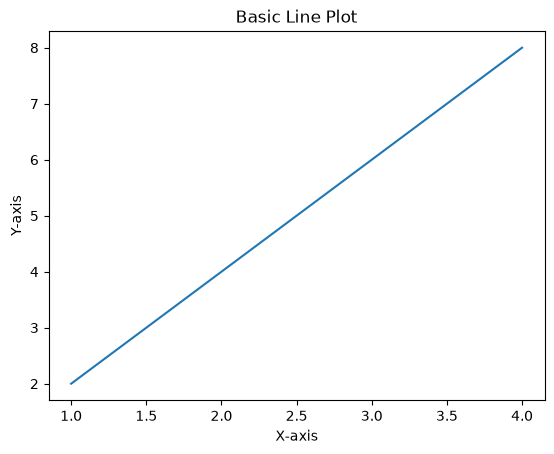

In [125]:
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [2, 4, 6, 8]

plt.plot(x, y)
plt.title("Basic Line Plot")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.show()

Here is what each line did:

- `plt.plot(x, y)` draws the line through the points `(1, 2)`, `(2, 4)`, `(3, 6)` and `(4, 8)`.
- `plt.title(...)` adds the title on top.
- `plt.xlabel(...)` and `plt.ylabel(...)` label the axes. A graph without labels is not a finished graph. Always label what is being measured, with units if it has any.
- `plt.show()` displays the figure. In notebooks the plot often appears even without it, but you should always write it. In a normal `.py` script, **nothing appears** without it.

What if `x` and `y` do not match in size?

ValueError: x and y must have same first dimension, but have shapes (4,) and (3,)

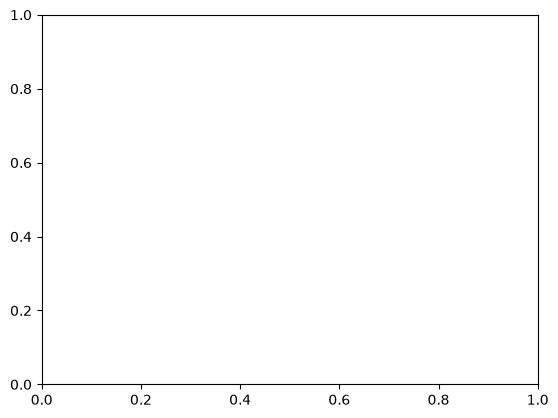

In [126]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3, 4], [2, 4, 6])
plt.show()

This gives `ValueError: x and y must have same first dimension, but have shapes (4,) and (3,)`.

Each point needs an `x` **and** a `y`. We gave four `x` values but only three `y` values, so the fourth point is incomplete. Always check `len(x) == len(y)`.

Matplotlib also works directly with NumPy arrays, which is great for plotting mathematical functions.

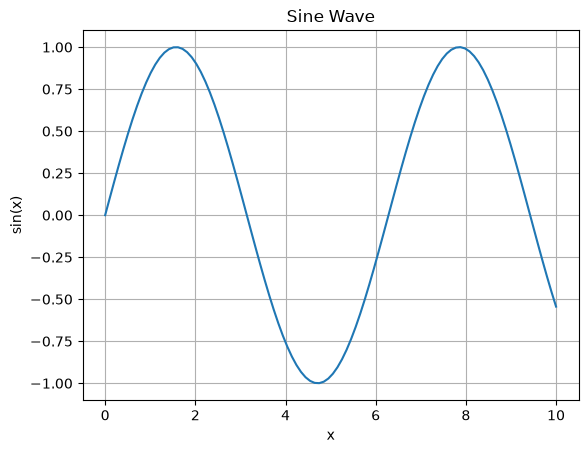

In [127]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 100)
y = np.sin(x)

plt.plot(x, y)
plt.title("Sine Wave")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

We used `np.linspace(0, 10, 100)` to make 100 evenly spaced points and `np.sin` to compute the sine of each one at once, which would have needed a loop with plain lists. This is the NumPy and Matplotlib team at work. `plt.grid(True)` adds grid lines to make the values easier to read.

#### Multiple lines and the legend

We can draw several lines on the same axes by calling `plt.plot()` more than once. Give each a `label`, and call `plt.legend()` to show which line is which.

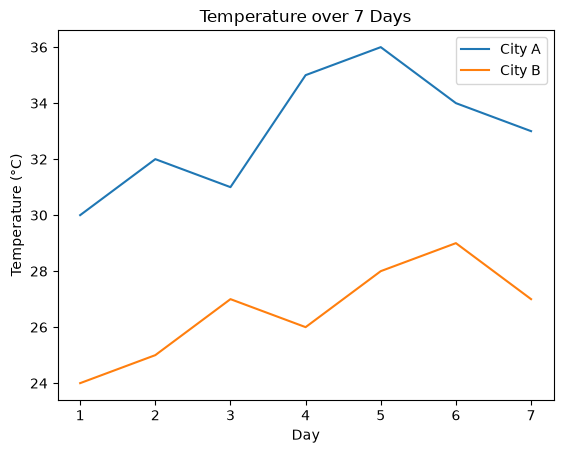

In [128]:
import matplotlib.pyplot as plt

days = [1, 2, 3, 4, 5, 6, 7]
city_a = [30, 32, 31, 35, 36, 34, 33]
city_b = [24, 25, 27, 26, 28, 29, 27]

plt.plot(days, city_a, label="City A")
plt.plot(days, city_b, label="City B")
plt.title("Temperature over 7 Days")
plt.xlabel("Day")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.show()

A common slip: using `label=...` but forgetting `plt.legend()`. The labels are stored but never displayed. Matplotlib gives only a warning (`No artists with labels found`) if you call `legend()` when no labels were given at all.

### Customizing plots 🎓

We can change the look of a line using extra arguments to `plt.plot()`.

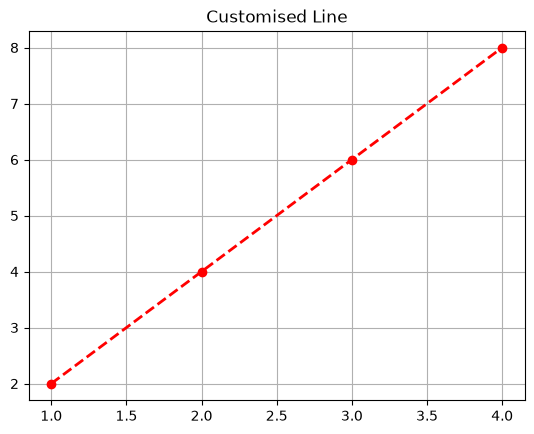

In [129]:
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [2, 4, 6, 8]

plt.plot(x, y, color="red", linestyle="--", marker="o", linewidth=2)
plt.title("Customised Line")
plt.grid(True)
plt.show()

| Argument | Meaning | Some values |
|---|---|---|
| `color` | Colour of the line | `"red"`, `"blue"`, `"green"`, `"#FF5733"` |
| `linestyle` | Style of the line | `"-"` solid, `"--"` dashed, `":"` dotted, `"-."` dash-dot |
| `marker` | Shape drawn at each point | `"o"` circle, `"s"` square, `"^"` triangle, `"*"` star |
| `linewidth` | Thickness | `1`, `2`, `3` ... |
| `label` | Name for the legend | any text |

There is a handy **shortcut format string** that packs marker, line and colour into one text, such as `"ro--"`, meaning red, circle markers, dashed line.

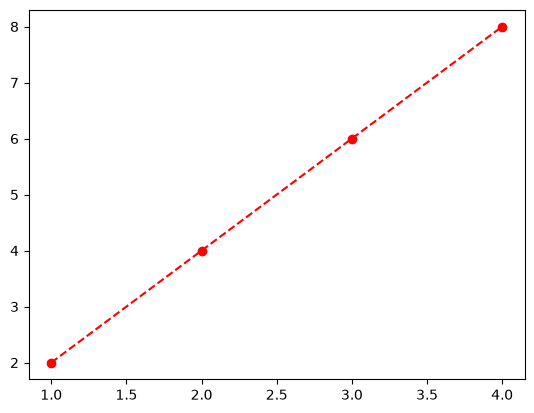

In [130]:
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [2, 4, 6, 8]

plt.plot(x, y, "ro--")
plt.show()

If you spell a colour or a style incorrectly, Matplotlib stops with an error.

ValueError: 'reddd' is not a valid value for color: supported inputs are (r, g, b) and (r, g, b, a) 0-1 float tuples; '#rrggbb', '#rrggbbaa', '#rgb', '#rgba' strings; named color strings; string reprs of 0-1 floats for grayscale values; 'C0', 'C1', ... strings for colors of the color cycle; and pairs combining one of the above with an alpha value

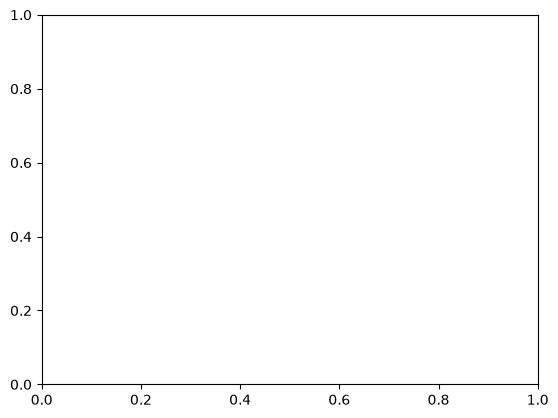

In [131]:
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [2, 4, 6, 8]

plt.plot(x, y, color="reddd")
plt.show()

This gives `ValueError: 'reddd' is not a valid value for color...`.

Matplotlib knows a fixed list of colour names. A misspelling is a very easy mistake, so when you see this error, look at the spelling first.

We can also control the **size** of the figure and the **range** of the axes.

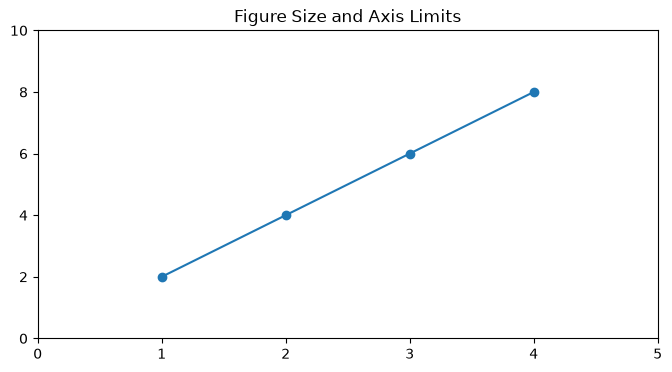

In [132]:
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [2, 4, 6, 8]

plt.figure(figsize=(8, 4))
plt.plot(x, y, marker="o")
plt.xlim(0, 5)
plt.ylim(0, 10)
plt.title("Figure Size and Axis Limits")
plt.show()

- `plt.figure(figsize=(8, 4))` makes the canvas 8 inches wide and 4 inches tall. It must come **before** the plotting calls.
- `plt.xlim()` and `plt.ylim()` set the visible range of each axis.

### Scatter plot 🎓

A **scatter plot** draws each pair `(x, y)` as a separate dot with no line joining them. It is the right choice to see if two variables are **related**, for example the hours studied and the marks scored.

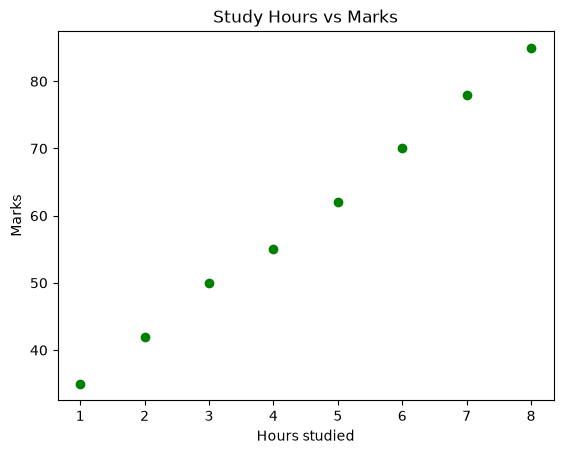

In [133]:
import matplotlib.pyplot as plt

hours = [1, 2, 3, 4, 5, 6, 7, 8]
marks = [35, 42, 50, 55, 62, 70, 78, 85]

plt.scatter(hours, marks, color="green")
plt.title("Study Hours vs Marks")
plt.xlabel("Hours studied")
plt.ylabel("Marks")
plt.show()

The dots rise from the bottom-left to the top-right: more study hours go with higher marks. This pattern is called a **positive correlation**. A scatter plot is the way to see correlation (and the starting point for **regression**, where we draw the best-fit line through such dots).

We can even check the correlation number with NumPy. A value of `+1` means a perfect positive relationship, `-1` a perfect negative one, and `0` no relationship.

In [134]:
import numpy as np

hours = [1, 2, 3, 4, 5, 6, 7, 8]
marks = [35, 42, 50, 55, 62, 70, 78, 85]

print(np.corrcoef(hours, marks)[0, 1])

0.9989662776940782


The value is very close to `+1`, which agrees with what the picture showed.

### Bar chart 🎓

A **bar chart** compares values across **categories**.

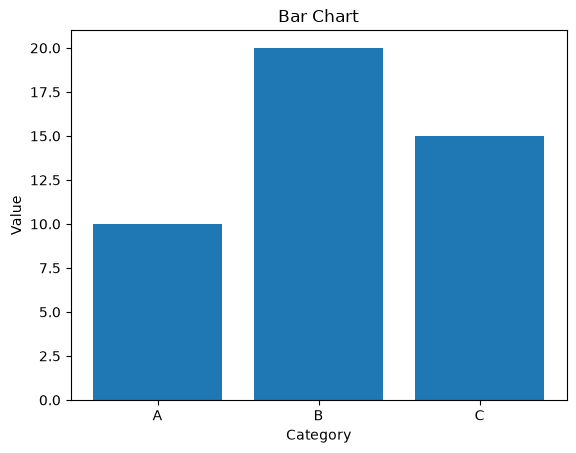

In [135]:
import matplotlib.pyplot as plt

categories = ["A", "B", "C"]
values = [10, 20, 15]

plt.bar(categories, values)
plt.title("Bar Chart")
plt.xlabel("Category")
plt.ylabel("Value")
plt.show()

Each category gets a bar, and the height is the value. With long category names, a **horizontal** bar chart is easier to read, using `plt.barh()`.

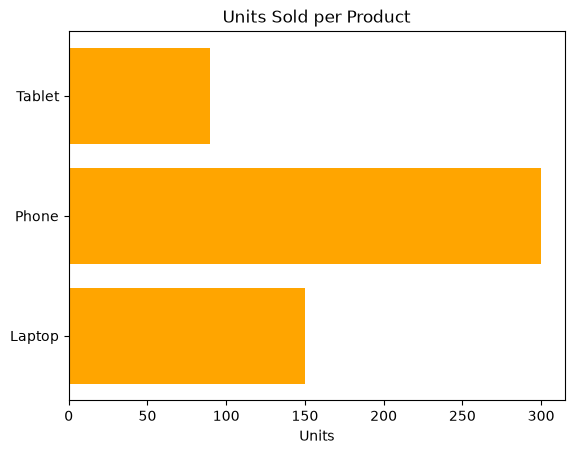

In [136]:
import matplotlib.pyplot as plt

products = ["Laptop", "Phone", "Tablet"]
units_sold = [150, 300, 90]

plt.barh(products, units_sold, color="orange")
plt.title("Units Sold per Product")
plt.xlabel("Units")
plt.show()

### Histogram 🎓

A **histogram** shows the **distribution** of a single numeric variable: how the values are spread. The data is split into ranges called **bins**, and the height of each bar is the count of values falling in that bin.

Note the difference from a bar chart: a bar chart compares categories, whereas a histogram groups **numbers** into ranges.

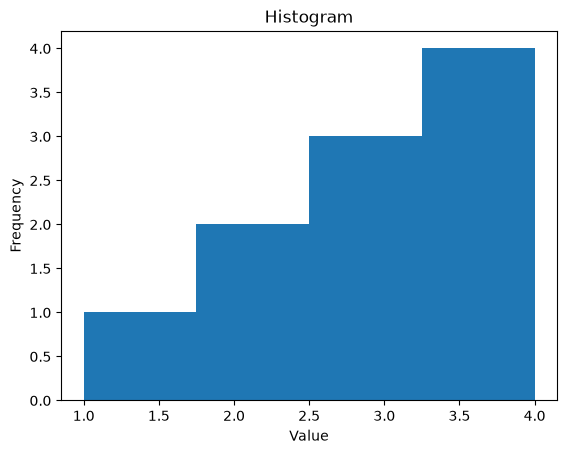

In [137]:
import matplotlib.pyplot as plt

data = [1, 2, 2, 3, 3, 3, 4, 4, 4, 4]

plt.hist(data, bins=4)
plt.title("Histogram")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()

The bars grow taller from left to right because `4` appears most often and `1` appears only once. The `bins` argument decides how many ranges to use. Too few bins hide the shape, too many make it jagged. Let's see this with a larger dataset from NumPy's random normal numbers.

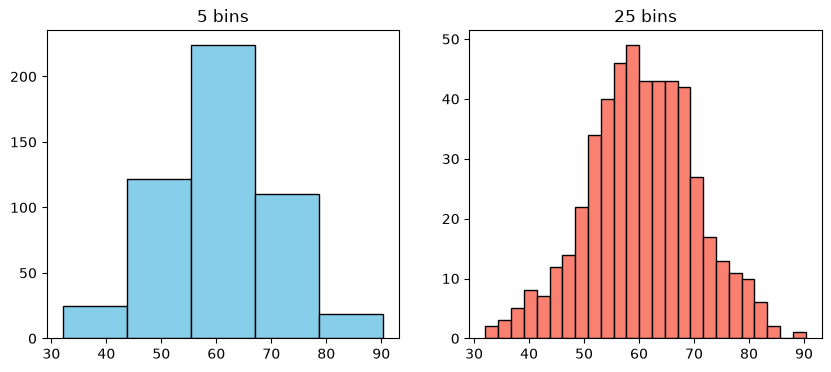

In [138]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)
exam_scores = np.random.normal(loc=60, scale=10, size=500)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(exam_scores, bins=5, color="skyblue", edgecolor="black")
plt.title("5 bins")

plt.subplot(1, 2, 2)
plt.hist(exam_scores, bins=25, color="salmon", edgecolor="black")
plt.title("25 bins")

plt.show()

We generated 500 exam scores around a mean of 60 and drew the same data twice. With 5 bins we get a rough outline, and with 25 bins we can clearly see the bell shape of a **normal distribution**. (We used `plt.subplot` to place two plots side by side. We will learn it properly in a moment.)

### Pie chart 🎓

A **pie chart** shows how a whole is divided into parts.

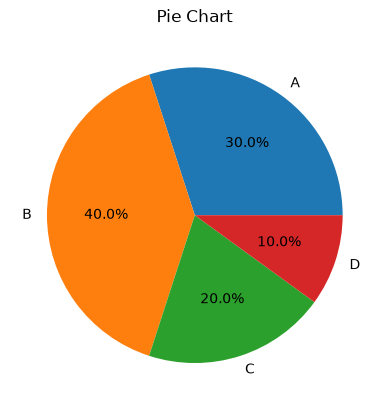

In [139]:
import matplotlib.pyplot as plt

sizes = [30, 40, 20, 10]
labels = ["A", "B", "C", "D"]

plt.pie(sizes, labels=labels, autopct="%1.1f%%")
plt.title("Pie Chart")
plt.show()

- `labels` names each slice.
- `autopct="%1.1f%%"` prints the percentage on each slice, with 1 decimal place. (The double `%%` is how we print a literal `%` sign.)

Pie charts have to be handled with care: the sizes represent shares of a total, so they cannot be negative.

ValueError: Wedge sizes 'x' must be non negative values

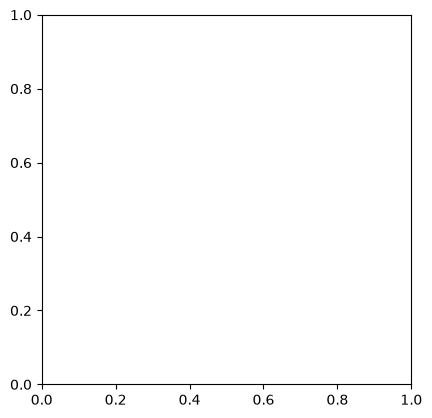

In [140]:
import matplotlib.pyplot as plt

plt.pie([30, -10, 20], labels=["A", "B", "C"])
plt.show()

This gives `ValueError: Wedge sizes must be non negative values`.

A slice of negative size makes no sense. Pie charts are best used with **few** categories (about 5 or fewer). For many categories or for exact comparisons, a bar chart is clearer.

We can pull a slice out to emphasise it with `explode`.

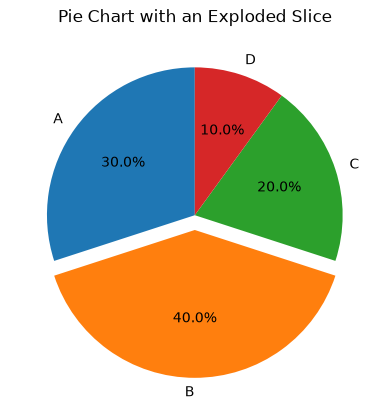

In [141]:
import matplotlib.pyplot as plt

sizes = [30, 40, 20, 10]
labels = ["A", "B", "C", "D"]

plt.pie(sizes, labels=labels, autopct="%1.1f%%", explode=[0, 0.1, 0, 0], startangle=90)
plt.title("Pie Chart with an Exploded Slice")
plt.show()

### Multiple plots: subplots

We can place several plots in one figure with `plt.subplots(rows, columns)`. It returns the **figure** and an array of **axes**, one per plot. We then draw on each axes using its own methods, which are named like `set_title` and `set_xlabel`.

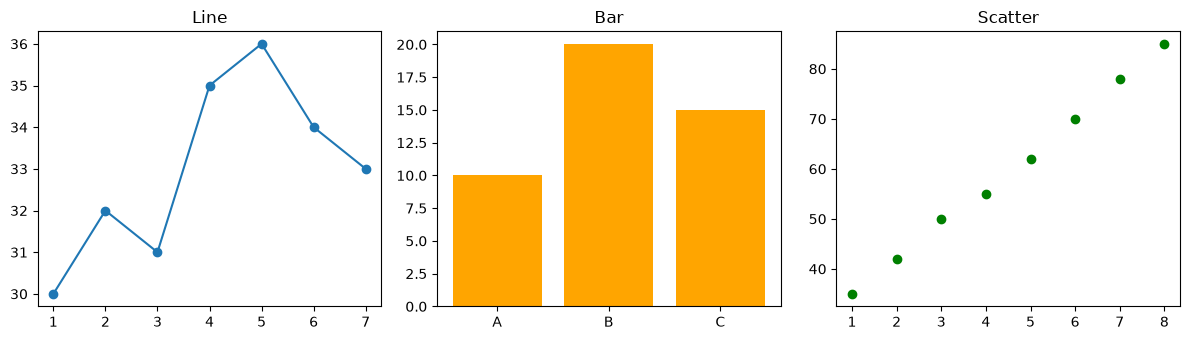

In [142]:
import matplotlib.pyplot as plt

days = [1, 2, 3, 4, 5, 6, 7]
city_a = [30, 32, 31, 35, 36, 34, 33]

categories = ["A", "B", "C"]
values = [10, 20, 15]

hours = [1, 2, 3, 4, 5, 6, 7, 8]
marks = [35, 42, 50, 55, 62, 70, 78, 85]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].plot(days, city_a, marker="o")
axes[0].set_title("Line")

axes[1].bar(categories, values, color="orange")
axes[1].set_title("Bar")

axes[2].scatter(hours, marks, color="green")
axes[2].set_title("Scatter")

plt.tight_layout()
plt.show()

`plt.subplots(1, 3)` made 1 row and 3 columns, so `axes` has three entries, `axes[0]`, `axes[1]` and `axes[2]`. `plt.tight_layout()` spaces them so that the titles and labels do not overlap.

With a grid of **2D** layout, such as `plt.subplots(2, 2)`, the axes need **two** indexes.

IndexError: index 3 is out of bounds for axis 0 with size 2

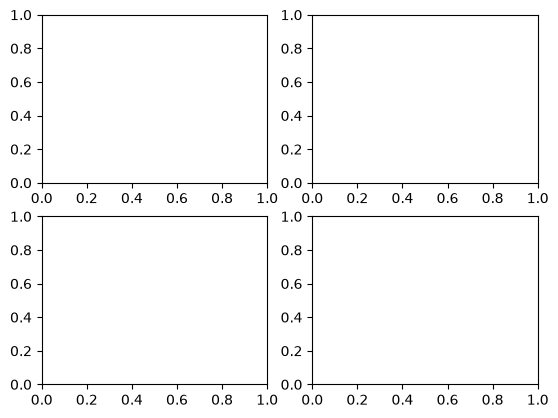

In [143]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2)
axes[3].plot([1, 2, 3])

This gives `IndexError: index 3 is out of bounds for axis 0 with size 2`.

With 2 rows and 2 columns, `axes` is itself a 2x2 NumPy array. So we have to write `axes[1, 1]` (or `axes[1][1]`) for the last plot. All that we learned about NumPy indexing applies here too.

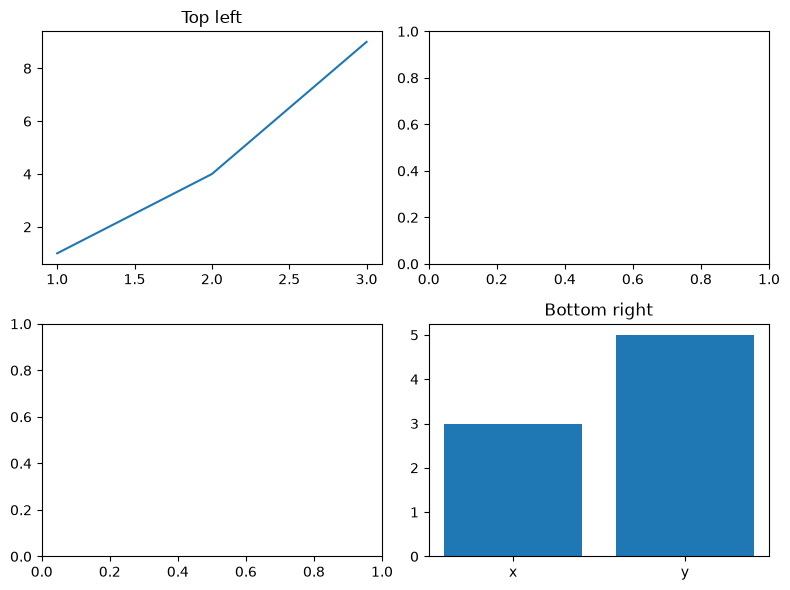

In [144]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(8, 6))

axes[0, 0].plot([1, 2, 3], [1, 4, 9])
axes[0, 0].set_title("Top left")

axes[1, 1].bar(["x", "y"], [3, 5])
axes[1, 1].set_title("Bottom right")

plt.tight_layout()
plt.show()

The two panels we did not draw on stay empty.

### Saving a figure

We can save the picture as an image file (PNG, JPG, PDF and more) with `plt.savefig()`. It must be called **before** `plt.show()`, because `show()` clears the figure afterwards.

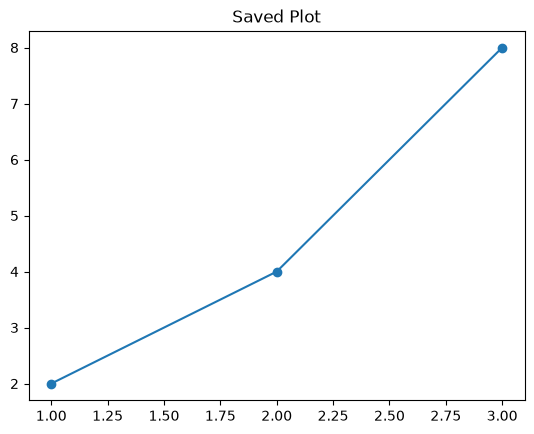

In [145]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3], [2, 4, 8], marker="o")
plt.title("Saved Plot")
plt.savefig("my_plot.png", dpi=150)
plt.show()

The file `my_plot.png` is now saved next to the notebook. `dpi` sets the resolution (the number of dots per inch).

### Matplotlib summary

| Task | Code |
|---|---|
| Line plot | `plt.plot(x, y)` |
| Scatter plot | `plt.scatter(x, y)` |
| Bar chart | `plt.bar(categories, values)`, `plt.barh(...)` for horizontal |
| Histogram | `plt.hist(data, bins=n)` |
| Pie chart | `plt.pie(sizes, labels=labels, autopct="%1.1f%%")` |
| Title and labels | `plt.title()`, `plt.xlabel()`, `plt.ylabel()` |
| Legend and grid | `plt.legend()`, `plt.grid(True)` |
| Figure size | `plt.figure(figsize=(w, h))` |
| Several plots | `fig, axes = plt.subplots(rows, cols)` |
| Save / display | `plt.savefig("name.png")`, `plt.show()` |

#### Which plot should I use?

| Question we want to answer | Plot |
|---|---|
| How does a value **change over time**? | Line |
| How do **categories compare**? | Bar |
| Are two numeric variables **related**? | Scatter |
| How is one numeric variable **distributed**? | Histogram |
| What is the **share** of each part? | Pie (few parts only) |

#### Common Matplotlib errors at a glance

| Error | Usual cause |
|---|---|
| `ValueError: x and y must have same first dimension` | `x` and `y` have different lengths |
| `ValueError: ... is not a valid value for color` | Misspelled colour or style name |
| `ValueError: Wedge sizes must be non negative` | Negative value in a pie chart |
| `IndexError` on `axes[...]` | Wrong index into the grid returned by `plt.subplots` |
| Nothing is displayed in a `.py` script | `plt.show()` is missing |
| Saved image is blank | `plt.savefig()` called after `plt.show()` |

## Putting it all together: sales analysis 🎓

Let's finish by using all three libraries in a single mini project, the way a real analysis flows:

1. **Load** the data (Pandas).
2. **Inspect and clean** it (Pandas).
3. **Calculate** new values (Pandas and NumPy).
4. **Visualize** the findings (Matplotlib).

We will use the same sales data as before. Since every cell is self-contained, each cell below creates the `sales.csv` file again and loads it.

In [146]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

print(df.shape)
print(df.isna().sum())
df

(6, 3)
Month      0
Revenue    0
Units      0
dtype: int64


,Month,Revenue,Units
0,Jan,12000,120
1,Feb,15000,150
2,Mar,14000,140
3,Apr,18000,180
4,May,21000,210
5,Jun,19000,190


Step 1 and 2: the file has 6 rows and 3 columns, and the count of missing values is `0` in every column, so there is nothing to clean.

Step 3: let's calculate a few values. First, the summary statistics.

In [147]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

# Summary statistics of the sales data
df.describe()

,Revenue,Units
count,6.000000,6.00000
mean,16500.000000,165.00000
std,3391.164992,33.91165
min,12000.000000,120.00000
25%,14250.000000,142.50000
50%,16500.000000,165.00000
75%,18750.000000,187.50000
max,21000.000000,210.00000


Now new calculated columns: the **revenue per unit**, and the month-to-month **growth**.

In [148]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

df["Price_per_Unit"] = df["Revenue"] / df["Units"]
df["Growth_%"] = df["Revenue"].pct_change() * 100

df

,Month,Revenue,Units,Price_per_Unit,Growth_%
0,Jan,12000,120,100.0,NaN
1,Feb,15000,150,100.0,25.000000
2,Mar,14000,140,100.0,-6.666667
3,Apr,18000,180,100.0,28.571429
4,May,21000,210,100.0,16.666667
5,Jun,19000,190,100.0,-9.523810


`pct_change()` calculates the percentage change from the previous row, so the first month has `NaN`: there is no earlier month to compare it with. Which month was the best, and which had the highest growth?

In [149]:
import pandas as pd

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

best = df.loc[df["Revenue"].idxmax()]
print("Best month :", best["Month"], "with revenue", best["Revenue"])

print("Total revenue :", df["Revenue"].sum())
print("Average units :", df["Units"].mean())
print("Months above average revenue:", df[df["Revenue"] > df["Revenue"].mean()]["Month"].tolist())

Best month : May with revenue 21000
Total revenue : 99000
Average units : 165.0
Months above average revenue: ['Apr', 'May', 'Jun']


`idxmax()` gives the **index label** of the largest value, and `df.loc[...]` then fetched that whole row. In this data, May was the best month.

Step 4: let's draw the story. One figure with two plots: revenue as bars and units as a line.

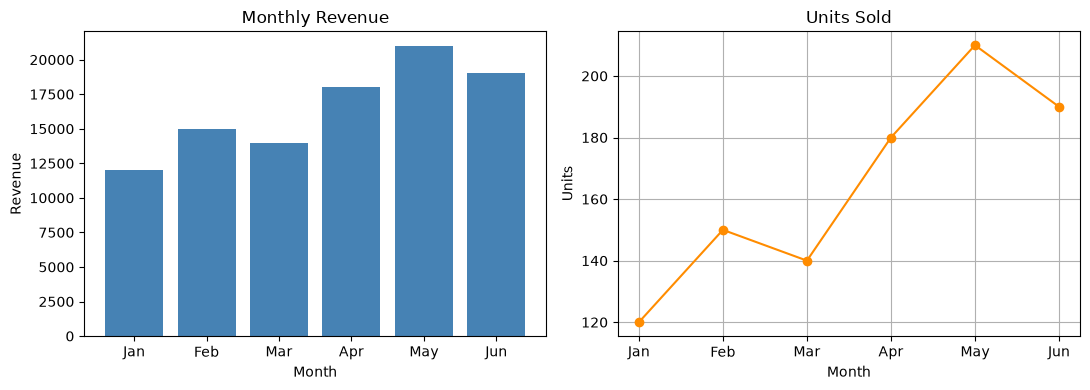

In [150]:
import pandas as pd
import matplotlib.pyplot as plt

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(df["Month"], df["Revenue"], color="steelblue")
axes[0].set_title("Monthly Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue")

axes[1].plot(df["Month"], df["Units"], marker="o", color="darkorange")
axes[1].set_title("Units Sold")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Units")
axes[1].grid(True)

plt.tight_layout()
plt.show()

The graphs show clearly what the table only hinted at: sales rose overall up to May (with a small dip in March) and then fell slightly in June.

Pandas can also draw directly from a DataFrame, using the `.plot` method, which uses Matplotlib behind the scenes. It is a shortcut for quick looks at the data.

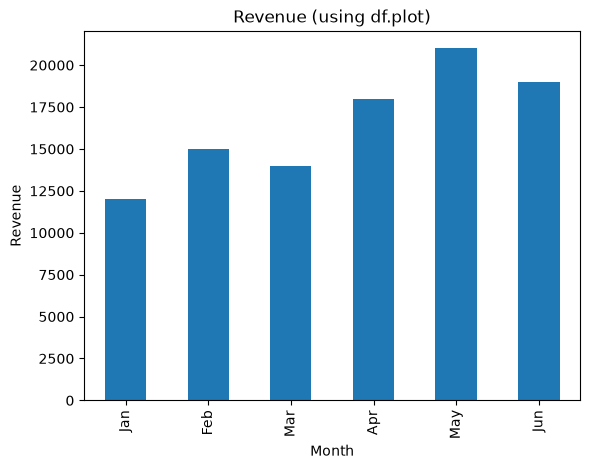

In [151]:
import pandas as pd
import matplotlib.pyplot as plt

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

df.plot(x="Month", y="Revenue", kind="bar", legend=False, title="Revenue (using df.plot)")
plt.ylabel("Revenue")
plt.show()

Finally, does the number of units sold relate to revenue? A scatter plot and the correlation will tell.

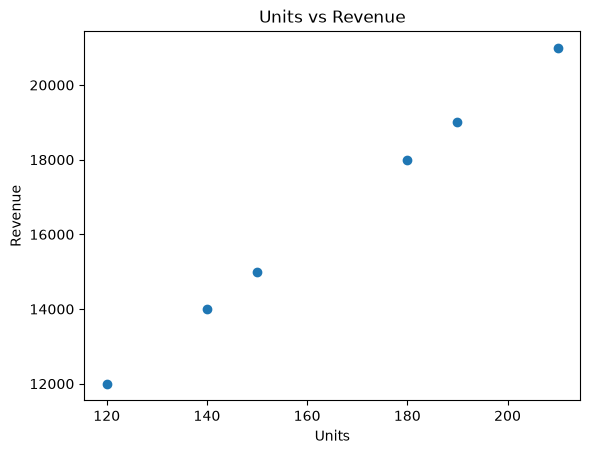

Correlation: 1.0


In [152]:
import pandas as pd
import matplotlib.pyplot as plt

sales = pd.DataFrame({
  "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
  "Revenue": [12000, 15000, 14000, 18000, 21000, 19000],
  "Units": [120, 150, 140, 180, 210, 190]
})
sales.to_csv("sales.csv", index=False)

df = pd.read_csv("sales.csv")

plt.scatter(df["Units"], df["Revenue"])
plt.title("Units vs Revenue")
plt.xlabel("Units")
plt.ylabel("Revenue")
plt.show()

print("Correlation:", df["Units"].corr(df["Revenue"]))

The points lie exactly on a straight line, and the correlation is `1.0`. This is because in our small dataset the price per unit is the same every month (we saw `100.0` in `Price_per_Unit`), so revenue is just units multiplied by that price. Real data is never this perfect, but the idea holds. And that straight-line relation is exactly what **linear regression** (`y = mx + c`) will model in the machine learning chapters ahead.

This small project followed the path of nearly every data science task: **load, inspect, clean, calculate, visualize**. The tools will get bigger, but the steps will stay the same.

## Summary 🎓

| Library | Used for | Core idea |
|---|---|---|
| NumPy | Fast numerical computation | The `ndarray`, vectorized operations and broadcasting |
| Pandas | Data manipulation and analysis | The `DataFrame`, with `loc` / `iloc`, filtering, `groupby`, missing data |
| Matplotlib | Visualization for insights | `plt.plot`, `scatter`, `bar`, `hist`, `pie`, and always label your axes |

#### The most important things to remember

- NumPy operations work **element by element**, with no loops needed. Shapes must match, or be **broadcastable**.
- `arr.shape` is `(rows, columns)`. `axis=0` works down the columns, `axis=1` works across the rows.
- Combine conditions with `&`, `|`, `~` and **parentheses**. Never use `and`, `or`, `not` on arrays or Series.
- `iloc` uses **positions** (end excluded), `loc` uses **labels** (end included).
- Most Pandas functions return a **new** DataFrame, so assign the result back if you want to keep the change.
- A `KeyError` is nearly always a typo in a column name. Print `df.columns`.
- Check for missing values with `df.isna().sum()` before doing any calculation.
- Choose the plot to match the question, and label the axes.

## Practice questions 🎓

Try these on your own first, using the lessons above.

1. Create a NumPy array of numbers from 1 to 20 and reshape it to 4x5.
2. Create a Pandas DataFrame of students with their marks and find the average marks.
3. Load a CSV file and display the first 10 rows.
4. Plot a line graph showing temperature changes over 7 days.
5. Create a bar chart comparing sales of three products.

When you are done, you have covered the full toolkit for handling and visualizing data.